# Семинар 06. Токенизация, эмбеддинги, FastText и embedding drift

Основа ноутбука — репозиторий [word2vec-pytorch](https://github.com/OlgaChernytska/word2vec-pytorch/tree/18d4f24c4d82dde76de9f6e4d88bbcbcf68befc2).

## План

| № | Блок | Что делаем |
|---|------|-----------|
| 0 | Подготовка | загрузка данных, импорты, конфиг |
| 1 | **Токенизация** | словарь, закон Ципфа, OOV; BPE и **Unigram LM** «с нуля»; SentencePiece |
| 2 | **Эмбеддинги и Word2Vec** | `nn.Embedding`, skip-gram, обучение, ближайшие соседи, аналогии |
| 3 | **FastText** | символьные n-граммы, обработка OOV |
| 4 | **Классификация тональности** | TF-IDF, усреднённые эмбеддинги, supervised FastText, TextCNN |
| 5 | **Embedding drift** | выравнивание пространств (Procrustes), семантический дрейф, дрейф версии модели, мониторинг в проде |

**Требования:** Python ≥ 3.10, PyTorch ≥ 2.0. GPU желателен (для обучения Word2Vec и TextCNN), но не обязателен.

> Ячейки с пометкой **«Теория»** можно читать как конспект, ячейки с пометкой **«Задание»** — для самостоятельной работы на семинаре.

## 0. Как текст становится входом нейросети

```
сырой текст ──► нормализация ──► токенизация ──►     словарь ──►    эмбеддинг ──►      модель
 "Unhappy!"      "unhappy !"     ["un","happy","!"]  [57, 981, 4]   3 вектора ∈ ℝᵈ     RNN / CNN / Transformer
```

Нейросеть работает только с числами, поэтому нужны два шага:

1. **Токенизация** — разбиваем строку на дискретные единицы (токены) и сопоставляем каждой целочисленный индекс.
2. **Эмбеддинг** — сопоставляем каждому индексу плотный вектор, который *обучается* так, чтобы похожие по смыслу токены оказались рядом.

От выбора токенизации зависят размер словаря, длина последовательностей, доля неизвестных слов и качество на редких словах. От эмбеддингов — то, какую «семантику» получит модель на входе.

## Подготовка: зависимости и данные

Данные:
* **WikiText-2** — статьи английской Википедии (~2 млн токенов), на нём учим Word2Vec и FastText;
* **Bumble reviews** — отзывы из Google Play, на них решаем задачу классификации тональности.

In [1]:
# %pip install sentencepiece fasttext-wheel
# Если при вызове fasttext.predict() увидите ошибку про numpy 2.x — ставьте numpy<2.

Defaulting to user installation because normal site-packages is not writeable
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 18.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.4/4.4 MB 51.7 MB/s eta 0:00:00

[notice] A new release of pip is available: 24.3.1 -> 26.2.1
[notice] To update, run: python -m pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [3]:
%%bash
set -e
if [ ! -d wikitext-2 ]; then
  curl -sL -o wikitext-2-v1.zip https://www.kaggle.com/api/v1/datasets/download/bestwater/wikitext-2-v1
  unzip -oq wikitext-2-v1.zip
fi
if [ ! -f bumble_google_play_reviews.csv ]; then
  curl -sL -o bumble-reviews.zip https://www.kaggle.com/api/v1/datasets/download/shivkumarganesh/bumble-dating-app-google-play-store-review
  unzip -oq bumble-reviews.zip
fi
ls -la wikitext-2 bumble_google_play_reviews.csv

-rw-r--r-- 1 user user 92695478 Oct 11 21:27 bumble_google_play_reviews.csv

wikitext-2:
total 12880
drwxr-xr-x 2 user user     4096 Oct 16 12:17 .
drwxr-xr-x 8 user user     4096 Oct 16 12:17 ..
-rw-r--r-- 1 user user  1256449 May 31  2024 wiki.test.tokens
-rw-r--r-- 1 user user 10797148 May 31  2024 wiki.train.tokens
-rw-r--r-- 1 user user  1121681 May 31  2024 wiki.valid.tokens


In [2]:
import math
import os
import random
import re
import sys
from collections import Counter, defaultdict
from itertools import chain

import numpy as np
import pandas as pd
import torch
from torch import nn
from torch.utils.data import Dataset, DataLoader
from tqdm.auto import tqdm
from IPython.display import clear_output, display

import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style('whitegrid')
plt.rcParams.update({'font.size': 14})

SEED = 42


def set_seed(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)


set_seed()
device = torch.device('cuda:0' if torch.cuda.is_available() else 'cpu')
print('device:', device)

device: cuda:0


In [3]:
TRAIN_TOKENS = 'wikitext-2/wiki.train.tokens'
VALID_TOKENS = 'wikitext-2/wiki.valid.tokens'

# --- Word2Vec ---
SKIPGRAM_N_WORDS = 4        # размер контекста с каждой стороны от центрального слова
MIN_WORD_FREQUENCY = 20     # слова реже этого порога превращаются в <unk>
MAX_SEQUENCE_LENGTH = 256   # длинные абзацы обрезаем
EMBED_DIM = 256
EMBED_MAX_NORM = 1
BATCH_SIZE = 16             # батч = 16 абзацев (пар «слово–контекст» в батче ~ десятки тысяч)
NUM_EPOCHS = 20

NUM_WORKERS = 4

# 1. Токенизация

## Теория: какие бывают токены

| Уровень | Пример: `unhappiness` | Плюсы | Минусы |
|---|---|---|---|
| **слова** | `unhappiness` | короткие последовательности, у токена есть смысл | огромный словарь, неизвестные слова (**OOV**), «run/runs/running» — три несвязанных токена |
| **символы** | `u n h a p p i n e s s` | нет OOV, крошечный словарь | длинные последовательности, символ почти не несёт смысла |
| **subword** | `un` `happi` `ness` | словарь фиксированного размера, редкое слово собирается из частых кусочков | результат зависит от алгоритма и корпуса |

Современные модели (BERT, GPT, T5, LLaMA…) почти всегда используют **subword**-токенизацию.

**Закон Ципфа.** Частота слова обратно пропорциональна его рангу: $f(r) \approx C / r^{s}$, $s \approx 1$. Следствие: небольшое число слов покрывает большую часть текста, но «длинный хвост» редких слов бесконечен — всегда найдутся слова, которых не было в обучающей выборке. Именно с хвостом борются subword-алгоритмы.

## 1.1 Загрузка и простая токенизация

Заменяем `torchtext.get_tokenizer("basic_english")` на регулярное выражение с тем же смыслом: нижний регистр, знаки препинания — отдельные токены. Разворачиваем служебные последовательности WikiText (`@-@`, `@,@`, `@.@` — это закодированные дефис, запятая и точка внутри слов и чисел).

> В WikiText-2 редкие слова уже заменены датасетом на `<unk>`. Реальный OOV-rate на «сырых» текстах был бы заметно выше — будем учитывать это при чтении графиков ниже.

In [4]:
TOKEN_RE = re.compile(r"<unk>|\w+(?:'\w+)?|[^\w\s]")


def tokenize(text):
    text = text.lower().replace(' @-@ ', '-').replace(' @,@ ', ',').replace(' @.@ ', '.')
    return TOKEN_RE.findall(text)


print(tokenize("The well @-@ known N'Sync's album sold 1 @,@ 000 copies <unk> !"))

['the', 'well', '-', 'known', "n'sync", "'", 's', 'album', 'sold', '1', ',', '000', 'copies', '<unk>', '!']


In [5]:
def load_and_preprocess_dataset(path, min_len=SKIPGRAM_N_WORDS * 2):
    """Одна строка файла WikiText = один абзац. Слишком короткие абзацы (заголовки, пустые строки) выбрасываем."""
    with open(path, encoding='utf-8') as file:
        lines = file.readlines()
    data = [tokenize(line) for line in lines]
    return [sent for sent in data if len(sent) > min_len]


train_data = load_and_preprocess_dataset(TRAIN_TOKENS)   # список абзацев, абзац = список токенов
valid_data = load_and_preprocess_dataset(VALID_TOKENS)

total_train_tokens = sum(len(sent) for sent in train_data)
total_valid_tokens = sum(len(sent) for sent in valid_data)

print(f'Num paragraphs: train - {len(train_data)}, valid - {len(valid_data)}')
print(f'Total tokens: train - {total_train_tokens}, valid - {total_valid_tokens}')
print(f'Average tokens per paragraph: {total_train_tokens / len(train_data):.2f}')

Num paragraphs: train - 17796, valid - 1898
Total tokens: train - 2039216, valid - 212955
Average tokens per paragraph: 114.59


Уникальных токенов в train: 28771
Слова длиннее 19 символов: {'diastereoselectivity': 3, 'compartmentalization': 2}


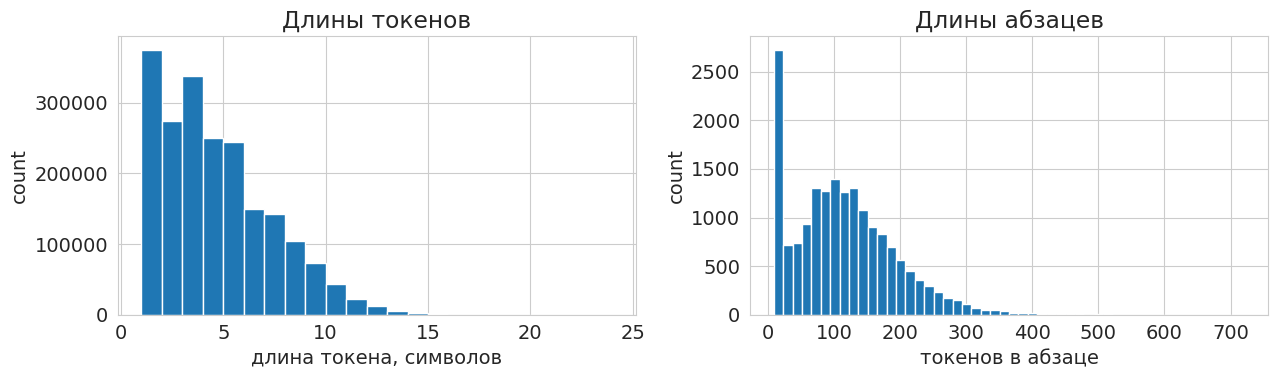

In [6]:
word_counts = Counter(chain.from_iterable(train_data))
print('Уникальных токенов в train:', len(word_counts))

# Самые длинные слова корпуса
long_words = {w: c for w, c in word_counts.items() if len(w) > 19}
print('Слова длиннее 19 символов:', long_words)

fig, axs = plt.subplots(1, 2, figsize=(13, 4))
axs[0].hist([len(w) for w in chain.from_iterable(train_data)], bins=range(1, 25))
axs[0].set(xlabel='длина токена, символов', ylabel='count', title='Длины токенов')
axs[1].hist([len(sent) for sent in train_data], bins=50)
axs[1].set(xlabel='токенов в абзаце', ylabel='count', title='Длины абзацев')
plt.tight_layout()
plt.show()

## 1.2 Закон Ципфа и проблема OOV

Построим график «ранг – частота» в логарифмических осях (у закона Ципфа это почти прямая) и посмотрим, как доля неизвестных токенов на валидации зависит от размера словаря (порога `min_freq`).

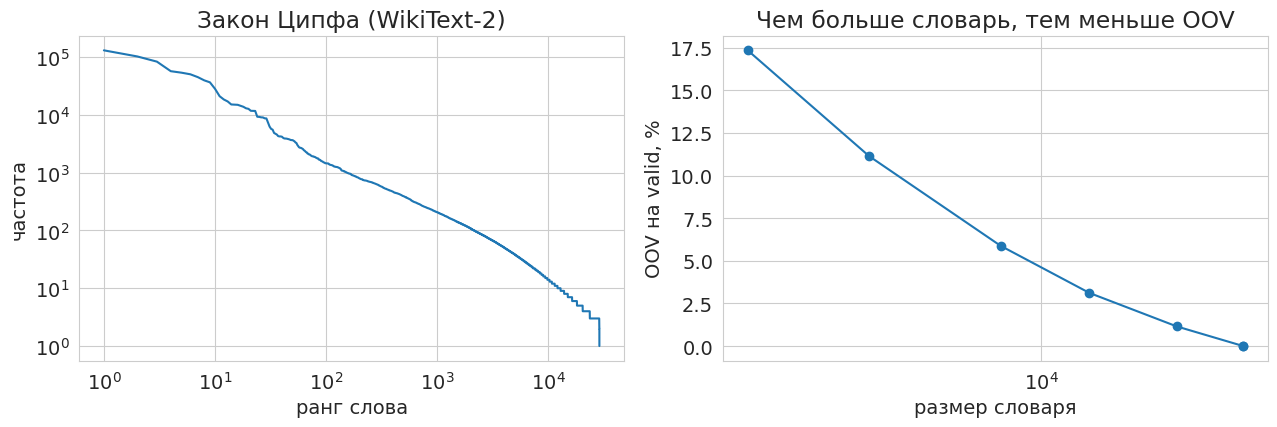

,min_freq,vocab_size,oov_rate_valid
0,1,28771,0.000000
1,2,28763,0.000000
2,5,20327,0.011491
3,10,12862,0.031143
4,20,8080,0.058792
5,50,4058,0.111427
6,100,2150,0.173459


In [7]:
freqs = np.array(sorted(word_counts.values(), reverse=True))
ranks = np.arange(1, len(freqs) + 1)

fig, axs = plt.subplots(1, 2, figsize=(13, 4.5))
axs[0].loglog(ranks, freqs)
axs[0].set(xlabel='ранг слова', ylabel='частота', title='Закон Ципфа (WikiText-2)')

valid_tokens = list(chain.from_iterable(valid_data))
rows = []
for min_freq in [1, 2, 5, 10, 20, 50, 100]:
    known = {w for w, c in word_counts.items() if c >= min_freq}
    oov_rate = np.mean([t not in known for t in valid_tokens])
    rows.append((min_freq, len(known), oov_rate))
oov_df = pd.DataFrame(rows, columns=['min_freq', 'vocab_size', 'oov_rate_valid'])

axs[1].plot(oov_df.vocab_size, oov_df.oov_rate_valid * 100, 'o-')
axs[1].set_xscale('log')
axs[1].set(xlabel='размер словаря', ylabel='OOV на valid, %', title='Чем больше словарь, тем меньше OOV')
plt.tight_layout()
plt.show()
oov_df

Вывод: словарь в ~8 тыс. слов (`min_freq=20`, как дальше в Word2Vec) оставляет часть токенов за бортом (см. таблицу), а увеличение словаря раздувает матрицу эмбеддингов и всё равно не убирает хвост. Нужен способ **собирать редкие слова из частых кусочков**.

## 1.3 Теория: subword-токенизация (BPE, WordPiece, Unigram)

Все три алгоритма строят словарь подслов фиксированного размера $|V|$ по корпусу, но по-разному.

**BPE (Byte-Pair Encoding, Sennrich et al., 2016).** Начинаем со словаря символов. Повторяем: находим самую частую пару соседних символов (токенов) в корпусе и **сливаем** её в новый токен. После $k$ слияний — словарь из символов и $k$ новых токенов. Кодирование нового слова: применяем выученные слияния в том же порядке. Детерминированно, жадно. Используется в GPT-2/3/4 (byte-level BPE), LLaMA, RoBERTa.

**WordPiece (BERT).** Похож на BPE, но пару для слияния выбирают по score $\dfrac{\text{freq}(ab)}{\text{freq}(a)\,\text{freq}(b)}$ (приближённо — по приросту правдоподобия). Кодирование — жадный поиск самого длинного подслова слева направо; продолжения помечаются `##`.

**Unigram LM (Kudo, 2018).** Принципиально другой подход — *вероятностная* модель. Мы **начинаем с большого словаря и удаляем** лишнее.

* Каждому токену $t$ из словаря $V$ приписана вероятность $p(t)$, $\sum_{t\in V} p(t)=1$.
* Токены независимы, поэтому вероятность сегментации $\mathbf{x}=(x_1,\dots,x_m)$ строки $X$:
$$P(\mathbf{x}) = \prod_{i=1}^{m} p(x_i)$$
* Токенизация — самая вероятная сегментация среди всех допустимых $S(X)$ (ищется алгоритмом Витерби за $O(n \cdot L)$, где $L$ — максимальная длина токена):
$$\mathbf{x}^{*}=\arg\max_{\mathbf{x}\in S(X)} P(\mathbf{x})$$
* Обучение — максимизация правдоподобия корпуса, где в игру вступают *все* сегментации слова:
$$\mathcal{L}=\sum_{s=1}^{|D|}\log P(X_s)=\sum_{s=1}^{|D|}\log\Big(\sum_{\mathbf{x}\in S(X_s)}P(\mathbf{x})\Big)$$

**Алгоритм обучения Unigram:**
1. Инициализация: все символы + много частых подстрок (например, 10⁶ самых частых).
2. **EM**: E-шаг — для каждого слова считаем *ожидаемое* число вхождений каждого токена (forward–backward по всем сегментациям); M-шаг — $p(t)=c(t)/\sum_{t'} c(t')$.
3. **Pruning**: для каждого токена считаем, насколько вырастет $-\mathcal{L}$, если его удалить; выкидываем ~20–25 % наименее полезных. Одиночные символы **не удаляем**, чтобы любую строку можно было записать.
4. Повторяем п. 2–3, пока $|V|$ не сократится до целевого.

| | BPE | Unigram LM |
|---|---|---|
| направление | словарь растёт (слияния) | словарь сокращается (pruning) |
| модель | набор правил слияния | вероятностная модель $p(t)$ |
| результат для слова | одна сегментация | наиболее вероятная **или любая из многих** (с вероятностями) |
| регуляризация | BPE-dropout | **subword regularization**: на обучении сэмплируем сегментацию |

Последнее свойство важно: на каждом шаге обучения модель может видеть *разные* разбиения одного слова — это аугментация, повышающая устойчивость к шуму и опечаткам.

## 1.4 BPE «с нуля» на игрушечном корпусе

Сначала BPE — он нужен как точка сравнения для Unigram. Корпус — слова с частотами, на котором хорошо видна морфология.

In [8]:
toy_corpus = {
    'low': 5, 'lower': 2, 'lowest': 3,
    'new': 6, 'newer': 4, 'newest': 7,
    'wide': 3, 'wider': 2, 'widest': 4,
}


def bpe_train(word_freqs, num_merges):
    corpus = {tuple(w): f for w, f in word_freqs.items()}  # слово -> кортеж символов
    merges = []
    for _ in range(num_merges):
        pairs = Counter()
        for symbols, f in corpus.items():
            for a, b in zip(symbols, symbols[1:]):
                pairs[(a, b)] += f
        if not pairs:
            break
        best = max(pairs, key=lambda p: (pairs[p], p))  # самая частая пара (детерминированный tie-break)
        merges.append(best)

        new_corpus = {}
        for symbols, f in corpus.items():
            out, i = [], 0
            while i < len(symbols):
                if i < len(symbols) - 1 and (symbols[i], symbols[i + 1]) == best:
                    out.append(symbols[i] + symbols[i + 1])
                    i += 2
                else:
                    out.append(symbols[i])
                    i += 1
            new_corpus[tuple(out)] = new_corpus.get(tuple(out), 0) + f
        corpus = new_corpus
    return merges


def bpe_encode(word, merges):
    symbols = list(word)
    for a, b in merges:  # применяем слияния строго в порядке обучения
        out, i = [], 0
        while i < len(symbols):
            if i < len(symbols) - 1 and symbols[i] == a and symbols[i + 1] == b:
                out.append(a + b)
                i += 2
            else:
                out.append(symbols[i])
                i += 1
        symbols = out
    return symbols


merges = bpe_train(toy_corpus, num_merges=8)
print('Слияния по порядку:', merges, '\n')
for w in ['lowest', 'newest', 'widest', 'wilder', 'wildest']:
    print(f'{w:>8} -> {bpe_encode(w, merges)}')

Слияния по порядку: [('n', 'e'), ('ne', 'w'), ('s', 't'), ('e', 'st'), ('o', 'w'), ('l', 'ow'), ('w', 'i'), ('wi', 'd')] 

  lowest -> ['low', 'est']
  newest -> ['new', 'est']
  widest -> ['wid', 'est']
  wilder -> ['wi', 'l', 'd', 'e', 'r']
 wildest -> ['wi', 'l', 'd', 'est']


Для простоты мы не добавляли маркер конца слова (`</w>`), как в оригинальной статье, и работаем со словами по отдельности; настоящие реализации (SentencePiece, HF `tokenizers`) используют пробел как часть токена (`▁`).

## 1.5 Unigram LM «с нуля»

Реализуем четыре кусочка из теории: Витерби, forward–backward (E-шаг), EM и pruning.

In [9]:
def substring_freqs(word_freqs, max_len):
    """Частота каждой подстроки длины ≤ max_len (с учётом частот слов)."""
    counts = Counter()
    for w, f in word_freqs.items():
        for i in range(len(w)):
            for j in range(i + 1, min(len(w), i + max_len) + 1):
                counts[w[i:j]] += f
    return counts


def viterbi_segment(word, logp, max_len):
    """Самая вероятная сегментация слова: динамическое программирование по позициям."""
    n = len(word)
    best = [-math.inf] * (n + 1)
    best[0] = 0.0
    back = [0] * (n + 1)
    for j in range(1, n + 1):
        for i in range(max(0, j - max_len), j):
            tok = word[i:j]
            if tok in logp and best[i] + logp[tok] > best[j]:
                best[j] = best[i] + logp[tok]
                back[j] = i
    tokens, j = [], n
    while j > 0:
        tokens.append(word[back[j]:j])
        j = back[j]
    return tokens[::-1], best[n]


def forward_backward(word, p, max_len):
    """Ожидаемое число вхождений каждого токена по ВСЕМ сегментациям слова + Z = сумма P(x) по всем сегментациям."""
    n = len(word)
    alpha = [0.0] * (n + 1)   # alpha[j] = суммарная вероятность всех способов записать word[:j]
    alpha[0] = 1.0
    for j in range(1, n + 1):
        for i in range(max(0, j - max_len), j):
            tok = word[i:j]
            if tok in p:
                alpha[j] += alpha[i] * p[tok]
    beta = [0.0] * (n + 1)    # beta[i] = суммарная вероятность всех способов записать word[i:]
    beta[n] = 1.0
    for i in range(n - 1, -1, -1):
        for j in range(i + 1, min(n, i + max_len) + 1):
            tok = word[i:j]
            if tok in p:
                beta[i] += p[tok] * beta[j]
    Z = alpha[n]
    expected = defaultdict(float)
    for i in range(n):
        for j in range(i + 1, min(n, i + max_len) + 1):
            tok = word[i:j]
            if tok in p:
                expected[tok] += alpha[i] * p[tok] * beta[j] / Z
    return expected, Z


def corpus_loss(word_freqs, p, max_len):
    """-L = -sum_s freq_s * log Z_s."""
    return -sum(f * math.log(forward_backward(w, p, max_len)[1]) for w, f in word_freqs.items())

In [10]:
def train_unigram(word_freqs, vocab_size, max_len=6, init_size=200, shrink=0.75, em_iters=3, verbose=True):
    sub = substring_freqs(word_freqs, max_len)
    chars = {t for t in sub if len(t) == 1}                       # одиночные символы удалять нельзя
    frequent = [t for t, _ in sub.most_common() if len(t) > 1][:init_size]
    vocab = chars | set(frequent)
    total = sum(sub[t] for t in vocab)
    p = {t: sub[t] / total for t in vocab}                        # начальные вероятности ~ частоты подстрок

    while True:
        # --- EM ---
        for _ in range(em_iters):
            counts = defaultdict(float)
            for w, f in word_freqs.items():
                expected, _ = forward_backward(w, p, max_len)     # E-шаг
                for t, v in expected.items():
                    counts[t] += f * v
            total = sum(counts.values())
            eps = 1e-6 * total                                        # одиночные символы остаются в словаре всегда
            p = {t: max(counts[t], eps) / total for t in p if counts[t] > 0 or len(t) == 1}  # M-шаг
        if verbose:
            print(f'|V| = {len(p):4d}   -logL = {corpus_loss(word_freqs, p, max_len):.3f}')
        if len(p) <= vocab_size:
            return p

        # Pruning: насколько вырастет -logL, если убрать токен
        base = corpus_loss(word_freqs, p, max_len)
        loss_increase = {}
        for t in p:
            if len(t) == 1:
                continue
            p_without = {k: v for k, v in p.items() if k != t}
            loss_increase[t] = corpus_loss(word_freqs, p_without, max_len) - base
        n_keep_multi = max(vocab_size, int(len(p) * shrink)) - len(chars)
        keep = set(sorted(loss_increase, key=loss_increase.get, reverse=True)[:max(n_keep_multi, 0)])
        p = {t: v for t, v in p.items() if len(t) == 1 or t in keep}
        z = sum(p.values())
        p = {t: v / z for t, v in p.items()}


UNI_MAX_LEN = 4
uni_p = train_unigram(toy_corpus, vocab_size=16, max_len=UNI_MAX_LEN)
print()
for t, v in sorted(uni_p.items(), key=lambda kv: -kv[1]):
    print(f'{t:>7s}  p = {v:.1e}')

|V| =   43   -logL = 101.954
|V| =   32   -logL = 96.781
|V| =   24   -logL = 96.687
|V| =   18   -logL = 96.686
|V| =   16   -logL = 96.686

    new  p = 2.9e-01
    est  p = 2.4e-01
    low  p = 1.7e-01
     er  p = 1.4e-01
    wid  p = 1.0e-01
   wide  p = 5.2e-02
      e  p = 1.0e-06
      s  p = 1.0e-06
      r  p = 1.0e-06
      i  p = 1.0e-06
      d  p = 1.0e-06
      w  p = 1.0e-06
      o  p = 1.0e-06
      n  p = 1.0e-06
      l  p = 1.0e-06
      t  p = 1.0e-06


In [11]:
uni_logp = {t: math.log(v) for t, v in uni_p.items()}

print(f'{"слово":>8} | {"BPE":<22} | Unigram (Витерби)')
for w in ['lowest', 'newest', 'widest', 'wilder', 'wildest']:
    uni_tokens, logprob = viterbi_segment(w, uni_logp, max_len=UNI_MAX_LEN)
    print(f'{w:>8} | {str(bpe_encode(w, merges)):<22} | {uni_tokens}   (log P = {logprob:.2f})')

   слово | BPE                    | Unigram (Витерби)
  lowest | ['low', 'est']         | ['low', 'est']   (log P = -3.18)
  newest | ['new', 'est']         | ['new', 'est']   (log P = -2.65)
  widest | ['wid', 'est']         | ['wid', 'est']   (log P = -3.69)
  wilder | ['wi', 'l', 'd', 'e', 'r'] | ['w', 'i', 'l', 'd', 'er']   (log P = -57.24)
 wildest | ['wi', 'l', 'd', 'est'] | ['w', 'i', 'l', 'd', 'est']   (log P = -56.68)


Ключевое отличие Unigram — у слова есть **распределение** по сегментациям, а не один правильный вариант. Перечислим все разбиения и их вероятности (для короткого слова их немного):

In [12]:
def all_segmentations(word, p, max_len):
    """Все допустимые сегментации с вероятностями P(x) = prod p(x_i). Экспоненциально — только для коротких слов!"""
    if not word:
        return [([], 1.0)]
    result = []
    for j in range(1, min(len(word), max_len) + 1):
        head = word[:j]
        if head in p:
            for tail, prob in all_segmentations(word[j:], p, max_len):
                result.append(([head] + tail, p[head] * prob))
    return result


ALPHA = 0.2   # сглаживание, как в SentencePiece: q(x) ∝ P(x)^alpha
segs = sorted(all_segmentations('widest', uni_p, UNI_MAX_LEN), key=lambda x: -x[1])
smoothed = [prob ** ALPHA for _, prob in segs]
Z = sum(smoothed)

print(f'Всего сегментаций «widest»: {len(segs)}\n')
print(f'{"сегментация":<28}{"P(x)":>12}{"q(x) при alpha=0.2":>22}')
for (tokens, prob), q in list(zip(segs, smoothed))[:6]:
    print(f'{str(tokens):<28}{prob:>12.2e}{q / Z:>22.1%}')

Всего сегментаций «widest»: 5

сегментация                         P(x)    q(x) при alpha=0.2
['wid', 'est']                  2.50e-02                 99.5%
['wide', 's', 't']              5.17e-14                  0.5%
['w', 'i', 'd', 'est']          2.41e-19                  0.0%
['wid', 'e', 's', 't']          1.03e-19                  0.0%
['w', 'i', 'd', 'e', 's', 't']    1.00e-36                  0.0%


Именно из этого распределения SentencePiece **сэмплирует** сегментации в режиме subword regularization — мы увидим это на реальных данных ниже.

### Задание 1.1 (обсуждение)
1. Измените `vocab_size` в `train_unigram` на 12 и на 25. Как меняются сегментации `lowest`, `wildest`? Почему слово `wildest`, которого не было в корпусе, всё равно сегментируется?
2. Чем E-шаг с forward–backward лучше «жёсткого» EM, где каждое слово разбивается только Витерби-сегментацией?
3. Почему при pruning нельзя удалять одиночные символы?

## 1.6 SentencePiece на реальных данных: BPE vs Unigram

[SentencePiece](https://github.com/google/sentencepiece) — библиотека, реализующая BPE и Unigram LM (она же использовалась в T5, ALBERT, XLNet и др.). Обучим обе модели на WikiText-2 с одинаковым размером словаря.

In [13]:
def clean_line(line):
    return (line.replace('<unk>', '').replace(' @-@ ', '-').replace(' @,@ ', ',').replace(' @.@ ', '.')).strip()


def dump_clean(src, dst):
    with open(src, encoding='utf-8') as fin, open(dst, 'w', encoding='utf-8') as fout:
        for line in fin:
            line = clean_line(line)
            if line:
                fout.write(line + '\n')


dump_clean(TRAIN_TOKENS, 'wt2_train_clean.txt')
dump_clean(VALID_TOKENS, 'wt2_valid_clean.txt')

In [14]:
%%capture
import sentencepiece as spm

SPM_VOCAB_SIZE = 4000
for model_type in ['bpe', 'unigram']:
    spm.SentencePieceTrainer.train(
        input='wt2_train_clean.txt',
        model_prefix=f'wt2_{model_type}',
        vocab_size=SPM_VOCAB_SIZE,
        model_type=model_type,
        character_coverage=1.0,
        normalization_rule_name='nmt_nfkc_cf',   # NFKC + приведение к нижнему регистру
    )

I0000 00:00:1792756546.782788     962 sentencepiece_trainer.cc:105] Starts training with : 
trainer_spec {
  input: wt2_train_clean.txt
  input_format: 
  model_prefix: wt2_bpe
  model_type: BPE
  vocab_size: 4000
  self_test_sample_size: 0
  character_coverage: 1
  input_sentence_size: 0
  shuffle_input_sentence: 1
  seed_sentencepiece_size: 1000000
  shrinking_factor: 0.75
  max_sentence_length: 4192
  num_threads: 16
  num_sub_iterations: 2
  max_sentencepiece_length: 16
  split_by_unicode_script: 1
  split_by_number: 1
  split_by_whitespace: 1
  split_digits: 0
  pretokenization_delimiter: 
  treat_whitespace_as_suffix: 0
  allow_whitespace_only_pieces: 0
  required_chars: 
  byte_fallback: 0
  vocabulary_output_piece_score: 1
  train_extremely_large_corpus: 0
  seed_sentencepieces_file: 
  hard_vocab_limit: 1
  use_all_vocab: 0
  unk_id: 0
  bos_id: 1
  eos_id: 2
  pad_id: -1
  unk_piece: <unk>
  bos_piece: <s>
  eos_piece: </s>
  pad_piece: <pad>
  unk_surface:  ⁇ 
  enable_diffe

In [15]:
import sentencepiece as spm

sp = {
    'bpe': spm.SentencePieceProcessor(model_file='wt2_bpe.model'),
    'unigram': spm.SentencePieceProcessor(model_file='wt2_unigram.model'),
}

examples = ['diastereoselectivity', 'compartmentalization', 'unhappiness', 'tokenization', 'transformers', 'covid-19']
for w in examples:
    print(w)
    for name, model in sp.items():
        print(f'   {name:8s}', model.encode(w, out_type=str))

diastereoselectivity
   bpe      ['▁di', 'aster', 'e', 'ose', 'lect', 'iv', 'ity']
   unigram  ['▁di', 'a', 'st', 'e', 're', 'o', 's', 'elect', 'i', 'v', 'i', 't', 'y']
compartmentalization
   bpe      ['▁comp', 'art', 'ment', 'al', 'ization']
   unigram  ['▁co', 'm', 'part', 'm', 'en', 't', 'a', 'l', 'i', 'z', 'at', 'i', 'on']
unhappiness
   bpe      ['▁un', 'h', 'app', 'iness']
   unigram  ['▁un', 'h', 'a', 'p', 'p', 'in', 'e', 's', 's']
tokenization
   bpe      ['▁to', 'ken', 'ization']
   unigram  ['▁to', 'k', 'en', 'i', 'z', 'at', 'i', 'on']
transformers
   bpe      ['▁trans', 'form', 'ers']
   unigram  ['▁transform', 'e', 'r', 's']
covid-19
   bpe      ['▁co', 'v', 'id', '-1', '9']
   unigram  ['▁co', 'v', 'i', 'd', '-19']


**Fertility** — среднее число токенов на слово: чем оно ближе к 1, тем короче последовательности. Сравним subword-токенизаторы со словарной моделью (где всё, что не попало в словарь, — один `<unk>`).

In [16]:
with open('wt2_valid_clean.txt', encoding='utf-8') as f:
    valid_lines = [line.strip() for line in f]
n_words = sum(len(line.split()) for line in valid_lines)

rows = []
for name, model in sp.items():
    n_tokens = sum(len(ids) for ids in model.encode(valid_lines))
    unk_rate = np.mean([i == model.unk_id() for ids in model.encode(valid_lines) for i in ids])
    rows.append((f'SentencePiece {name} (V={SPM_VOCAB_SIZE})', n_tokens / n_words, unk_rate))

word_vocab = {w for w, c in word_counts.items() if c >= MIN_WORD_FREQUENCY}
rows.append((f'словарная (V={len(word_vocab)})', 1.0, np.mean([t not in word_vocab for t in valid_tokens])))

pd.DataFrame(rows, columns=['токенизация', 'токенов на слово (fertility)', 'доля <unk>']).round(4)

,токенизация,токенов на слово (fertility),доля <unk>
0,SentencePiece bpe (V=4000),1.3535,0.0000
1,SentencePiece unigram (V=4000),1.4465,0.0000
2,словарная (V=8080),1.0000,0.0588


Как правило, subwords дают почти нулевую долю `<unk>` при вдвое меньшем словаре — ценой более длинных последовательностей (fertility > 1).

### Subword regularization: сэмплирование сегментаций

Для Unigram мы можем получать *разные* токенизации одного и того же слова с вероятностями, пропорциональными $P(\mathbf{x})$ (параметр `alpha` сглаживает распределение: чем меньше, тем «равномернее»). Для BPE аналог — **BPE-dropout** (`alpha` — вероятность пропустить слияние). На обучении модель видит разные разбиения одного слова — это аугментация, особенно полезная для устойчивости к опечаткам и морфологии.

In [17]:
word = 'compartmentalization'
print('Unigram, детерминированно:', sp['unigram'].encode(word, out_type=str))
print('\nUnigram, сэмплирование (alpha=0.2):')
for _ in range(5):
    print('   ', sp['unigram'].encode(word, out_type=str, enable_sampling=True, alpha=0.2, nbest_size=-1))
print('\nBPE-dropout (p=0.2):')
for _ in range(5):
    print('   ', sp['bpe'].encode(word, out_type=str, enable_sampling=True, alpha=0.2))

Unigram, детерминированно: ['▁co', 'm', 'part', 'm', 'en', 't', 'a', 'l', 'i', 'z', 'at', 'i', 'on']

Unigram, сэмплирование (alpha=0.2):
    ['▁', 'com', 'part', 'm', 'en', 't', 'a', 'l', 'i', 'z', 'a', 't', 'i', 'on']
    ['▁co', 'm', 'part', 'm', 'en', 't', 'a', 'l', 'i', 'z', 'a', 't', 'i', 'on']
    ['▁co', 'm', 'part', 'm', 'en', 't', 'a', 'l', 'i', 'z', 'a', 't', 'i', 'on']
    ['▁co', 'm', 'part', 'm', 'en', 't', 'a', 'l', 'i', 'z', 'a', 't', 'i', 'on']
    ['▁co', 'm', 'part', 'm', 'e', 'n', 't', 'a', 'l', 'i', 'z', 'a', 't', 'i', 'on']

BPE-dropout (p=0.2):
    ['▁c', 'om', 'par', 't', 'ment', 'a', 'l', 'iz', 'ation']
    ['▁', 'com', 'p', 'art', 'ment', 'al', 'ization']
    ['▁comp', 'art', 'ment', 'al', 'ization']
    ['▁comp', 'art', 'ment', 'al', 'ization']
    ['▁c', 'om', 'p', 'art', 'ment', 'al', 'ization']


### Задание 1.2
1. Сравните токенизацию `diastereoselectivity` у BPE и Unigram. Какая сегментация лучше соответствует морфемам?
2. Обучите Unigram с `vocab_size=500` и `vocab_size=16000`. Как меняются fertility и качество сегментации редких слов? Какой компромисс между размером словаря и длиной последовательностей?
3. Токенизируйте русское предложение моделью, обученной на английской Википедии. Что происходит с fertility и почему?

# 2. Эмбеддинги и Word2Vec

## Теория: что такое эмбеддинг

**One-hot** представление слова — вектор длины $|V|$ с единственной единицей. Оно плохо по двум причинам: огромная размерность и **отсутствие геометрии** — любые два разных слова ортогональны, $\cos(\text{кот},\text{котёнок}) = \cos(\text{кот},\text{ракета}) = 0$.

**Эмбеддинг** — плотный вектор небольшой размерности $d \ll |V|$ (обычно 50–1000), который *обучается* так, чтобы геометрия отражала смысл. Все эмбеддинги хранятся в матрице $E \in \mathbb{R}^{|V| \times d}$, а эмбеддинг слова с индексом $i$ — это $i$-я строка:
$$e_i = \text{onehot}_i^{\top} E = E[i]$$
Умножение на one-hot — то же, что выбор строки, поэтому на практике делают просто индексацию (lookup). Именно это делает слой `nn.Embedding`.

**Дистрибутивная гипотеза** (Harris, Firth): *слова, встречающиеся в похожих контекстах, имеют похожие значения*. На ней построены Word2Vec, GloVe и FastText: мы не задаём смысл вручную, а заставляем векторы предсказывать контекст.

**Косинусная близость** — стандартная мера «похожести» эмбеддингов (не зависит от длины вектора):
$$\cos(u,v)=\frac{u^\top v}{\|u\|\,\|v\|}$$

## Теория: Word2Vec (Mikolov et al., 2013)

Две архитектуры:
* **Skip-gram** — по центральному слову $w_c$ предсказываем слова контекста из окна $\pm m$. Лучше работает на редких словах.
* **CBOW** — по контексту предсказываем центральное слово. Быстрее, лучше для частых слов.

Мы реализуем skip-gram. Функция потерь для текста длины $T$:
$$\mathcal{L}=-\frac{1}{T}\sum_{t=1}^{T}\ \sum_{\substack{-m\le j\le m\\ j\neq 0}}\log P(w_{t+j}\mid w_t),\qquad P(o\mid c)=\frac{\exp(u_o^\top v_c)}{\sum_{w\in V}\exp(u_w^\top v_c)}$$

* $v_c$ — «входной» вектор центрального слова (строка матрицы `nn.Embedding`),
* $u_o$ — «выходной» вектор слова контекста (строка весов `nn.Linear`-декодера).

Итоговыми эмбеддингами обычно берут $v$ (иногда $(v+u)/2$).

**Цена softmax.** Знаменатель — сумма по всему словарю: $O(|V|\cdot d)$ на каждую пару. Для $|V|\sim 10^6$ это неприемлемо, поэтому в оригинале используют **negative sampling**: вместо softmax решаем задачу бинарной классификации «пара настоящая / случайная»:
$$\log\sigma(u_o^\top v_c)+\sum_{k=1}^{K}\mathbb{E}_{n_k\sim P_n}\log\sigma(-u_{n_k}^\top v_c),\qquad P_n(w)\propto f(w)^{3/4}$$
У нас $|V|\approx 8000$, поэтому честный softmax + `CrossEntropyLoss` дёшев и проще для понимания. Ещё одна деталь оригинала, которую мы опускаем, — *subsampling* частых слов (слово `the` выбрасывается из обучающих пар с вероятностью $1-\sqrt{t/f(w)}$).



## 2.1 `nn.Embedding` — это таблица поиска

`nn.Embedding(num_embeddings, embedding_dim)` хранит матрицу весов `weight` формы `(|V|, d)`. Покажем, что lookup эквивалентен умножению one-hot вектора на эту матрицу.

In [24]:
demo_emb = nn.Embedding(num_embeddings=10, embedding_dim=4)
ids = torch.tensor([2, 5, 2])

lookup = demo_emb(ids)                                                        # индексация строк
one_hot = torch.nn.functional.one_hot(ids, num_classes=10).float()
matmul = one_hot @ demo_emb.weight                                             # one-hot @ E

print('weight:', tuple(demo_emb.weight.shape), '| lookup:', tuple(lookup.shape))
print('lookup == one_hot @ E :', torch.allclose(lookup, matmul))

weight: (10, 4) | lookup: (3, 4)
lookup == one_hot @ E : True


## 2.2 Словарь и обучающие пары

Словарь строим сами: индекс `0` отдаём под `<unk>`, остальные индексы — слова с частотой ≥ `MIN_WORD_FREQUENCY`, упорядоченные по убыванию частоты.

In [19]:
class Vocab:
    def __init__(self, sentences, min_freq, unk='<unk>'):
        self.counts = Counter(chain.from_iterable(sentences))
        self.itos = [unk] + [w for w, c in self.counts.most_common() if c >= min_freq and w != unk]
        self.stoi = {w: i for i, w in enumerate(self.itos)}

    def __len__(self):
        return len(self.itos)

    def __getitem__(self, token):          # неизвестный токен -> 0 (<unk>)
        return self.stoi.get(token, 0)

    def __call__(self, tokens):
        return [self.stoi.get(t, 0) for t in tokens]


vocab = Vocab(train_data, min_freq=MIN_WORD_FREQUENCY)
VOCAB_SIZE = len(vocab)
print(f'Vocab size: {VOCAB_SIZE}')
print('Топ-10 слов:', vocab.itos[:10])
print(vocab(train_data[10][:8]), '<-', train_data[10][:8])

Vocab size: 8080
Топ-10 слов: ['<unk>', 'the', ',', '.', 'of', 'and', 'in', 'to', 'a', '"']
[1, 1018, 4, 975, 519, 17, 477, 195] <- ['the', 'majority', 'of', 'material', 'created', 'for', 'previous', 'games']


Как из предложения получаются обучающие пары «центральное слово → слово контекста» при окне $m=2$ (в ноутбуке $m=4$, `SKIPGRAM_N_WORDS`):

In [20]:
demo = ['the', 'quick', 'brown', 'fox', 'jumps', 'over', 'the', 'lazy', 'dog']
m = 4
for idx in range(m, len(demo) - m):
    center = demo[idx]
    context = demo[idx - m: idx] + demo[idx + 1: idx + m + 1]
    print(f'{center:>6} -> {context}')
print('\nПервые и последние m слов центральными не становятся — для них не хватает контекста (так сделано в collate_fn ниже).')

 brown -> ['the', 'quick', 'fox', 'jumps']
   fox -> ['quick', 'brown', 'jumps', 'over']
 jumps -> ['brown', 'fox', 'over', 'the']
  over -> ['fox', 'jumps', 'the', 'lazy']
   the -> ['jumps', 'over', 'lazy', 'dog']

Первые и последние m слов центральными не становятся — для них не хватает контекста (так сделано в collate_fn ниже).


`collate_fn` превращает батч абзацев в два длинных тензора: на каждую пару — индекс центрального слова (`batch_input`) и индекс одного слова контекста (`batch_output`). Для окна из 8 слов центральное слово повторяется 8 раз:

```
батч_input : [5 5 5 5 5 5 5 5 | 6 6 6 6 6 6 6 6 | ...]    # центральное слово, повторённое 2m раз
батч_output: [1 2 3 4 6 7 8 9 | 2 3 4 5 7 8 9 10| ...]    # слова контекста
```

In [21]:
def collate_fn(batch):
    """
    Collate_fn для skip-gram. `batch` — список абзацев (списков токенов).

    Контекст — SKIPGRAM_N_WORDS слов слева и SKIPGRAM_N_WORDS слов справа.
    Абзацы длиннее MAX_SEQUENCE_LENGTH обрезаются.

    batch_input[i]  — центральное слово, batch_output[i] — слово контекста.
    """
    batch_input, batch_output = [], []
    for text in batch:
        text_tokens_ids = vocab(text)

        if MAX_SEQUENCE_LENGTH:
            text_tokens_ids = text_tokens_ids[:MAX_SEQUENCE_LENGTH]

        for idx in range(len(text_tokens_ids) - SKIPGRAM_N_WORDS * 2):
            token_id_sequence = text_tokens_ids[idx: idx + SKIPGRAM_N_WORDS * 2 + 1]
            input_ = token_id_sequence.pop(SKIPGRAM_N_WORDS)   # центральное слово
            outputs = token_id_sequence                        # оставшиеся 2m слов — контекст

            batch_input += [input_] * len(outputs)
            batch_output += outputs

    batch_input = torch.tensor(batch_input, dtype=torch.long)
    batch_output = torch.tensor(batch_output, dtype=torch.long)
    return batch_input, batch_output


def make_loader(data, shuffle):
    return DataLoader(data, batch_size=BATCH_SIZE, num_workers=NUM_WORKERS,
                      pin_memory=torch.cuda.is_available(), collate_fn=collate_fn, shuffle=shuffle)


train_loader = make_loader(train_data, shuffle=True)
valid_loader = make_loader(valid_data, shuffle=False)

# Проверим на маленьком примере, что пары собираются правильно
x_demo, y_demo = collate_fn([train_data[10][:SKIPGRAM_N_WORDS * 2 + 2]])
print('shapes:', x_demo.shape, y_demo.shape)
print([(vocab.itos[i], vocab.itos[o]) for i, o in zip(x_demo[:8].tolist(), y_demo[:8].tolist())])

shapes: torch.Size([16]) torch.Size([16])
[('created', 'the'), ('created', 'majority'), ('created', 'of'), ('created', 'material'), ('created', 'for'), ('created', 'previous'), ('created', 'games'), ('created', ',')]


## 2.3 Модель и обучение

Модель — две матрицы: `embeds` ($|V|\times d$, эмбеддинги $v$) и `decoder` ($d \to |V|$, содержит выходные векторы $u$ и смещение). По индексу центрального слова берём $v_c$ и считаем логиты по всему словарю.

`max_norm=1` означает, что при каждом обращении строки эмбеддинга с нормой > 1 *на лету* масштабируются до нормы 1 — это ограничивает рост векторов и стабилизирует обучение.

In [22]:
class Word2VecModel(nn.Module):
    def __init__(self, embed_dim, embed_max_norm, vocab_size):
        super().__init__()
        self.embeds = nn.Embedding(num_embeddings=vocab_size, embedding_dim=embed_dim, max_norm=embed_max_norm)
        self.decoder = nn.Linear(embed_dim, vocab_size)

    def forward(self, tokens):
        embeds = self.embeds(tokens)      # (N,) -> (N, d)
        logits = self.decoder(embeds)     # (N, d) -> (N, |V|)
        return logits


def build_w2v(seed, num_epochs):
    set_seed(seed)
    model = Word2VecModel(EMBED_DIM, EMBED_MAX_NORM, VOCAB_SIZE).to(device)
    optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, num_epochs)
    criterion = nn.CrossEntropyLoss()
    return model, optimizer, scheduler, criterion


tmp_model = Word2VecModel(EMBED_DIM, EMBED_MAX_NORM, VOCAB_SIZE)
print('embeds.weight:', tuple(tmp_model.embeds.weight.shape), '| decoder.weight:', tuple(tmp_model.decoder.weight.shape))
del tmp_model

embeds.weight: (8080, 256) | decoder.weight: (8080, 256)


In [23]:
def plot_w2v_losses(train_losses, valid_losses):
    clear_output(wait=True)
    plt.figure(figsize=(6, 4))
    plt.plot(range(1, len(train_losses) + 1), train_losses, label='train', color='deepskyblue', linewidth=2)
    plt.plot(range(1, len(valid_losses) + 1), valid_losses, label='valid', color='springgreen', linewidth=2)
    plt.ylabel('loss')
    plt.xlabel('epoch')
    plt.legend()
    plt.show()


def w2v_training_epoch(model, optimizer, criterion, loader, desc):
    total_loss, num_batches = 0.0, 0
    model.train()
    for inputs, outputs in tqdm(loader, desc=desc, leave=False):
        inputs, outputs = inputs.to(device), outputs.to(device)

        optimizer.zero_grad()
        loss = criterion(model(inputs), outputs)
        loss.backward()
        optimizer.step()

        total_loss += loss.item()
        num_batches += 1
    return total_loss / num_batches


@torch.no_grad()
def w2v_validation_epoch(model, criterion, loader, desc):
    total_loss, num_batches = 0.0, 0
    model.eval()
    for inputs, outputs in tqdm(loader, desc=desc, leave=False):
        inputs, outputs = inputs.to(device), outputs.to(device)
        total_loss += criterion(model(inputs), outputs).item()
        num_batches += 1
    return total_loss / num_batches


def train_w2v(model, optimizer, scheduler, criterion, train_loader, valid_loader, num_epochs):
    train_losses, valid_losses = [], []
    for epoch in range(1, num_epochs + 1):
        train_losses.append(w2v_training_epoch(model, optimizer, criterion, train_loader, f'Training {epoch}/{num_epochs}'))
        valid_losses.append(w2v_validation_epoch(model, criterion, valid_loader, f'Validating {epoch}/{num_epochs}'))
        if scheduler is not None:
            scheduler.step()
        plot_w2v_losses(train_losses, valid_losses)
    return train_losses, valid_losses

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7f5334ff1f30>
Traceback (most recent call last):
  File "/opt/conda/lib/python3.10/site-packages/torch/utils/data/dataloader.py", line 1479, in __del__
    self._shutdown_workers()
  File "/opt/conda/lib/python3.10/site-packages/torch/utils/data/dataloader.py", line 1443, in _shutdown_workers
    w.join(timeout=_utils.MP_STATUS_CHECK_INTERVAL)
  File "/opt/conda/lib/python3.10/multiprocessing/process.py", line 149, in join
    res = self._popen.wait(timeout)
  File "/opt/conda/lib/python3.10/multiprocessing/popen_fork.py", line 40, in wait
    if not wait([self.sentinel], timeout):
  File "/opt/conda/lib/python3.10/multiprocessing/connection.py", line 931, in wait
    ready = selector.select(timeout)
  File "/opt/conda/lib/python3.10/selectors.py", line 416, in select
    fd_event_list = self._selector.poll(timeout)
KeyboardInterrupt: 


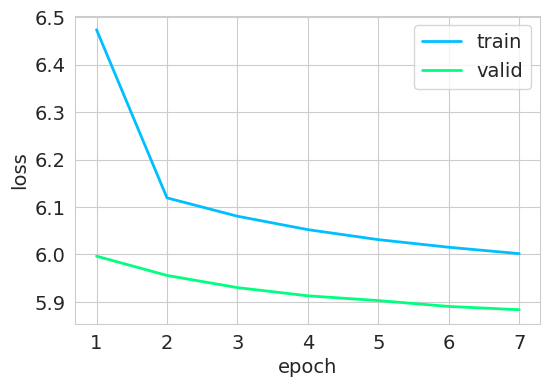

Training 8/20:   0%|          | 0/1113 [00:00<?, ?it/s]

KeyboardInterrupt: 

In [25]:
model, optimizer, scheduler, criterion = build_w2v(seed=SEED, num_epochs=NUM_EPOCHS)
train_losses, valid_losses = train_w2v(model, optimizer, scheduler, criterion, train_loader, valid_loader, NUM_EPOCHS)
torch.save(model.state_dict(), 'w2v_base.pt')

## 2.4 Что выучили эмбеддинги

Достаём матрицу эмбеддингов (веса `embeds`) и ищем ближайших соседей по косинусной близости. Функция `most_similar` понимает и арифметику над векторами: `'king - man + woman'`. Слова запроса исключаются из выдачи (стандартный протокол для аналогий — иначе ответом почти всегда будет само слово из запроса), а `<unk>` не показываем.

In [31]:
embed_matrix = model.embeds.weight.detach().cpu().numpy()   # (|V|, d)


def l2_normalize(E):
    return E / np.clip(np.linalg.norm(E, axis=1, keepdims=True), 1e-8, None)


def parse_query(query):
    """'king - man + woman' -> [(+1,'king'), (-1,'man'), (+1,'woman')]"""
    return [(-1 if sign == '-' else 1, word) for sign, word in re.findall(r'([+-]?)\s*([^\s+-]+)', query)]


def most_similar(query, E, vocab, topn=5, verbose=True):
    En = l2_normalize(E)
    vec, used = np.zeros(E.shape[1]), []
    for sign, word in parse_query(query):
        idx = vocab[word]
        if idx == 0:
            print(f'  [!] слова "{word}" нет в словаре, пропускаем')
            continue
        vec += sign * En[idx]
        used.append(idx)
    sims = En @ (vec / (np.linalg.norm(vec) + 1e-8))
    sims[[0] + used] = -np.inf                       # не показываем <unk> и слова самого запроса
    top = np.argsort(-sims)[:topn]
    result = [(vocab.itos[i], float(sims[i])) for i in top]
    if verbose:
        print(f'{query!r}: ' + ', '.join(f'{w} ({s:.2f})' for w, s in result))
    return result


for q in ['woman', 'kick', 'help', 'king', 'london', 'january']:
    most_similar(q, embed_matrix, vocab, topn=6)

'woman': girl (0.86), man (0.84), child (0.82), herself (0.79), figure (0.78), young (0.77)
'kick': touchdown (0.88), tech (0.87), penalty (0.87), ecu (0.86), goal (0.86), hokies (0.85)
'help': keep (0.82), try (0.81), accept (0.80), get (0.80), trying (0.79), bring (0.78)
'king': henry (0.90), edward (0.90), lord (0.89), pope (0.86), elizabeth (0.85), queen (0.85)
'london': theatre (0.81), toronto (0.79), college (0.76), museum (0.75), manhattan (0.75), university (0.74)
'january': november (0.97), june (0.97), april (0.96), march (0.96), december (0.96), february (0.95)


In [ ]:
most_similar('king - man + woman', embed_matrix, vocab, topn=8)
most_similar('paris - france + england', embed_matrix, vocab, topn=8);

'king - man + woman': lord (0.81), legend (0.79), queen (0.79), bishop (0.78), reign (0.77), nephew (0.77), edward (0.77), chancellor (0.76)
'paris - france + england': theatre (0.79), everton (0.75), retirement (0.75), liverpool (0.75), club (0.74), inaugural (0.73), cup (0.73), atlético (0.73)


Может быть такое, в первых позициях для `king − man + woman` встречаются `son`, `lord`, `henry`, а не `queen`. Это нормально: WikiText-2 — всего ~2 млн токенов, а известные красивые аналогии появляются на корпусах в миллиарды токенов. Измерим качество не на единичных примерах, а на небольшом наборе аналогий $a:b = c:d$ (слова, которых нет в словаре, пропускаются):

In [ ]:
analogies = [
    ('man', 'woman', 'king', 'queen'), ('boy', 'girl', 'brother', 'sister'), ('he', 'she', 'his', 'her'),
    ('france', 'paris', 'england', 'london'), ('france', 'paris', 'germany', 'berlin'),
    ('france', 'paris', 'italy', 'rome'), ('japan', 'tokyo', 'china', 'beijing'),
    ('is', 'was', 'are', 'were'), ('one', 'first', 'two', 'second'),
]


def analogy_eval(quads, E, vocab, topk=(1, 5)):
    En = l2_normalize(E)
    hits, used = {k: 0 for k in topk}, 0
    for a, b, c, d in quads:
        ids = [vocab[w] for w in (a, b, c, d)]
        if 0 in ids:
            continue
        used += 1
        sims = En @ (En[ids[1]] - En[ids[0]] + En[ids[2]])
        sims[[0] + ids[:3]] = -np.inf
        order = np.argsort(-sims)[:max(topk)]
        for k in topk:
            hits[k] += int(ids[3] in order[:k])
    return used, {f'top-{k}': hits[k] / max(used, 1) for k in topk}


used, scores = analogy_eval(analogies, embed_matrix, vocab)
print(f'Использовано аналогий: {used} из {len(analogies)};', scores)

Использовано аналогий: 8 из 9; {'top-1': 0.25, 'top-5': 0.375}


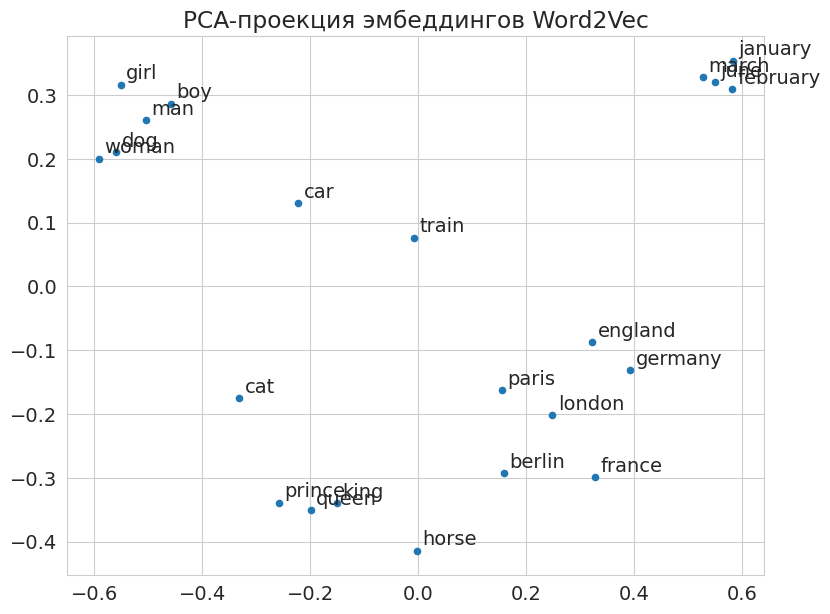

In [ ]:
from sklearn.decomposition import PCA

words = ['king', 'queen', 'prince', 'man', 'woman', 'boy', 'girl', 'france', 'paris', 'england', 'london',
         'germany', 'berlin', 'january', 'february', 'march', 'june', 'dog', 'cat', 'horse', 'car', 'train']
words = [w for w in words if vocab[w] != 0]
coords = PCA(n_components=2, random_state=SEED).fit_transform(l2_normalize(embed_matrix)[[vocab[w] for w in words]])

plt.figure(figsize=(9, 7))
plt.scatter(coords[:, 0], coords[:, 1], s=20)
for (x, y), w in zip(coords, words):
    plt.annotate(w, (x, y), xytext=(4, 4), textcoords='offset points')
plt.title('PCA-проекция эмбеддингов Word2Vec')
plt.show()

### Задание 2

1. **Окно.** Обучите модель с `SKIPGRAM_N_WORDS=2` и `=8`. Какие соседи более «синтаксические», а какие более «тематические»?
2. Почему матрица $E$ имеет `max_norm=1`, а косинусная близость от этого не зависит?

# 3. FastText

## Теория: от слов к символьным n-граммам

Word2Vec даёт каждому слову из словаря *независимый* вектор. Отсюда две проблемы: слова вне словаря получают `<unk>`, а однокоренные `run / runs / running` не имеют ничего общего в параметрах.

**FastText** (Bojanowski et al., 2017) представляет слово как мешок **символьных n-грамм**. Слово окружают маркерами границ `<` и `>`, чтобы отличать префиксы/суффиксы от середины слова, и берут все n-граммы длин от `minn` (3) до `maxn` (6). Например, для `where` и $n=3$:
```
<wh  whe  her  ere  re>      + само слово  <where>
```
Вектор слова — сумма векторов его n-грамм (и вектора самого слова, если оно есть в словаре):
$$v_w=\sum_{g\in G(w)} z_g,\qquad s(w,c)=v_w^\top u_c$$
Обучение — тот же skip-gram с negative sampling. Векторы n-грамм хранятся в хеш-таблице фиксированного размера (по умолчанию 2·10⁶ «корзин»), так что память не зависит от числа разных n-грамм.

| | Word2Vec | FastText |
|---|---|---|
| единица обучения | слово | символьные n-граммы слова |
| слово вне словаря (OOV) | `<unk>` | вектор из n-грамм — **получаем всегда** |
| опечатки, морфология | не обрабатывает | устойчив (общие n-граммы) |
| размер модели | $\|V\|\times d$ | $\|V\|\times d + B\times d$ ($B$ — число корзин) |

Для **классификации** у FastText есть ещё и supervised-режим: берём усреднённые эмбеддинги слов (и n-грамм слов) документа и обучаем линейный классификатор поверх — об этом в разделе 4.

In [26]:
def char_ngrams(word, minn=3, maxn=6):
    """Символьные n-граммы слова с маркерами границ (как в fastText)."""
    w = f'<{word}>'
    return [w[i:i + n] for n in range(minn, maxn + 1) for i in range(len(w) - n + 1)
            if not (i == 0 and n == len(w))]    # n-грамма, равная всему слову, — это отдельный токен слова


print('where, n=3     :', char_ngrams('where', 3, 3))
print('center, n=3..4 :', char_ngrams('center', 3, 4))
print('\nОбщие n-граммы у «unhappy» и «unhappiness»:',
      sorted(set(char_ngrams('unhappy')) & set(char_ngrams('unhappiness'))))

where, n=3     : ['<wh', 'whe', 'her', 'ere', 're>']
center, n=3..4 : ['<ce', 'cen', 'ent', 'nte', 'ter', 'er>', '<cen', 'cent', 'ente', 'nter', 'ter>']

Общие n-граммы у «unhappy» и «unhappiness»: ['<un', '<unh', '<unha', '<unhap', 'app', 'hap', 'happ', 'nha', 'nhap', 'nhapp', 'unh', 'unha', 'unhap', 'unhapp']


Обучим маленький FastText на WikiText-2 и проверим, как он ведёт себя на словах, которых модель не видела, — в отличие от нашего Word2Vec, который выдал бы для них индекс `<unk>`.

In [ ]:
pip install fasttext

In [27]:
import fasttext

with open('wt2_tokens.txt', 'w', encoding='utf-8') as f:
    for sent in train_data:
        f.write(' '.join(t for t in sent if t != '<unk>') + '\n')

ft_wiki = fasttext.train_unsupervised('wt2_tokens.txt', model='skipgram', dim=100, minn=3, maxn=6,
                                      minCount=5, epoch=10, thread=4, verbose=0)
ft_wiki_words = set(ft_wiki.words)
print('Слов в словаре FastText:', len(ft_wiki_words))

Слов в словаре FastText: 20327


In [28]:
def cos_np(a, b):
    return float(a @ b / (np.linalg.norm(a) * np.linalg.norm(b)))


for w in ['kingg', 'diastereoselectivity', 'unhappyness', 'compartmentalisation']:
    in_ft = w in ft_wiki_words
    w2v_idx = vocab[w]
    print(f'{w!r}: в словаре FastText: {in_ft}; в словаре Word2Vec: {w2v_idx != 0} (индекс {w2v_idx}, т.е. <unk>)')
    print('    ближайшие в FastText:', [(n, round(s, 2)) for s, n in ft_wiki.get_nearest_neighbors(w, k=5)])

print('\ncos(king, kingg)     =', round(cos_np(ft_wiki.get_word_vector('king'), ft_wiki.get_word_vector('kingg')), 3))
print('cos(king, banana)    =', round(cos_np(ft_wiki.get_word_vector('king'), ft_wiki.get_word_vector('banana')), 3))

'kingg': в словаре FastText: False; в словаре Word2Vec: False (индекс 0, т.е. <unk>)
    ближайшие в FastText: [('king', 0.89), ('kingship', 0.85), ('kings', 0.82), ('kingsley', 0.76), ('kingdoms', 0.75)]
'diastereoselectivity': в словаре FastText: False; в словаре Word2Vec: False (индекс 0, т.е. <unk>)
    ближайшие в FastText: [('selectivity', 0.88), ('inactivity', 0.74), ('activity', 0.7), ('enantioselective', 0.7), ('reactivity', 0.69)]
'unhappyness': в словаре FastText: False; в словаре Word2Vec: False (индекс 0, т.е. <unk>)
    ближайшие в FastText: [('unhappy', 0.87), ('unwillingness', 0.76), ('loneliness', 0.75), ('illness', 0.72), ('greatness', 0.71)]
'compartmentalisation': в словаре FastText: False; в словаре Word2Vec: False (индекс 0, т.е. <unk>)
    ближайшие в FastText: [('compartment', 0.85), ('compartments', 0.78), ('apartment', 0.66), ('orientalis', 0.64), ('departments', 0.63)]

cos(king, kingg)     = 0.885
cos(king, banana)    = 0.226


In [29]:
query = ft_wiki.get_word_vector('king') - ft_wiki.get_word_vector('man') + ft_wiki.get_word_vector('woman')

In [37]:
most_similar("king - man + woman", ft_wiki.get_input_matrix(), vocab)

IndexError: list index out of range

Опечатка `kingg` получает осмысленный вектор, близкий к `king`, потому что у них почти все n-граммы общие. Для Word2Vec такого слова не существует.

### Задание 3
1. Обучите FastText с `minn=2, maxn=3` и с `minn=4, maxn=6`. Как меняются соседи слов `unhappyness` и `compartmentalisation`?
2. Сравните соседей слова `running` в `ft_wiki` и в нашем Word2Vec. Какая модель лучше группирует словоформы?
3. Почему у FastText обычно *хуже* качество на «семантических» аналогиях, но *лучше* на «синтаксических» (`good → better`)?

# 4. Классификация тональности: от TF-IDF до FastText и TextCNN

Задача: по тексту отзыва в Google Play на приложение Bumble определить, положительный он (оценка ≥ 4) или нет. Сравним четыре подхода — от разреженных признаков до свёрток над предобученными эмбеддингами:

1. **TF-IDF + логистическая регрессия** — сильный baseline на разреженных признаках;
2. **усреднённые эмбеддинги FastText + логистическая регрессия** — «bag of embeddings», порядок слов теряется;
3. **supervised FastText** — обучаем классификатор целиком (эмбеддинги слов и биграмм + линейный слой);
4. **TextCNN** над последовательностью предобученных эмбеддингов — учитывает локальный порядок слов.

Отзывов: 183603; доля положительных (score >= 4): 0.354


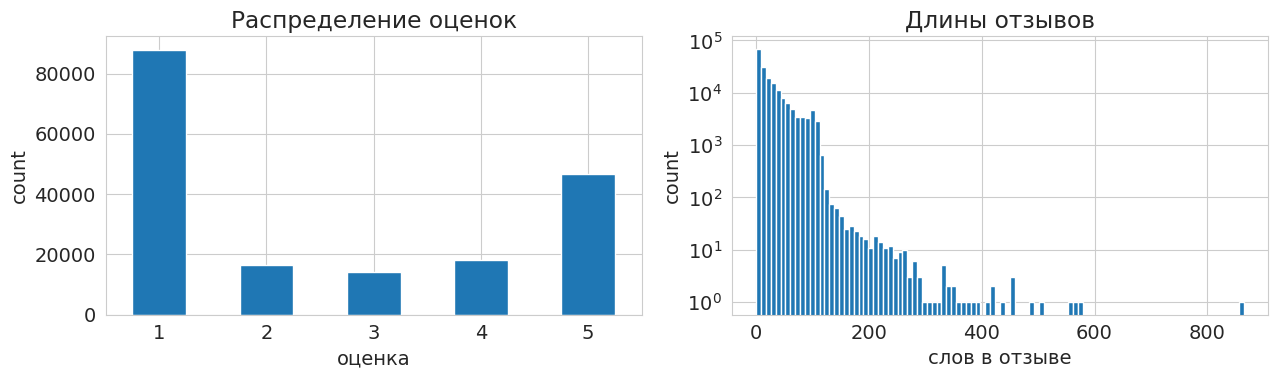

In [42]:
data = pd.read_csv('bumble_google_play_reviews.csv')
data = data[data.content.notna()].reset_index(drop=True)
data['tokens'] = data.content.apply(tokenize)
data = data[data.tokens.str.len() > 0].reset_index(drop=True)   # отзывы только из эмодзи/пробелов уже токенизируются, пустые — выбрасываем

X = data.tokens.to_list()
y = (data.score >= 4).to_numpy().astype(int)
print(f'Отзывов: {len(X)}; доля положительных (score >= 4): {y.mean():.3f}')

fig, axs = plt.subplots(1, 2, figsize=(13, 4))
data.score.value_counts().sort_index().plot.bar(ax=axs[0], rot=0)
axs[0].set(xlabel='оценка', ylabel='count', title='Распределение оценок')
axs[1].hist([len(sent) for sent in X], bins=100)
axs[1].set(yscale='log', xlabel='слов в отзыве', ylabel='count', title='Длины отзывов')
plt.tight_layout()
plt.show()

In [43]:
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score

# Делим индексы (а не списки), чтобы потом легко сопоставлять признаки и отзывы
idx_train, idx_test = train_test_split(np.arange(len(X)), test_size=0.25, random_state=SEED)
X_train, X_test = [X[i] for i in idx_train], [X[i] for i in idx_test]
y_train, y_test = y[idx_train], y[idx_test]
print(len(X_train), len(X_test))

results = {}   # название метода -> accuracy на тесте

137702 45901


## 4.1 Baseline: TF-IDF + LogReg

$\text{tf-idf}(t,d)=\text{tf}(t,d)\cdot\log\frac{N}{\text{df}(t)}$ — слово важно в документе, если часто встречается в нём и редко — в коллекции.

In [44]:
X_train_sents = [' '.join(sent) for sent in X_train]
X_test_sents = [' '.join(sent) for sent in X_test]

tf_idf = TfidfVectorizer(min_df=5).fit(X_train_sents)
tf_idf_train, tf_idf_test = tf_idf.transform(X_train_sents), tf_idf.transform(X_test_sents)
print('Размерность признаков:', tf_idf_train.shape[1])

lr_tfidf = LogisticRegression(max_iter=1000).fit(tf_idf_train, y_train)
print(f'Tf-idf + LogRegr train acc: {accuracy_score(lr_tfidf.predict(tf_idf_train), y_train):.4f}')
results['TF-IDF + LogReg'] = accuracy_score(lr_tfidf.predict(tf_idf_test), y_test)
print(f'Tf-idf + LogRegr test acc:  {results["TF-IDF + LogReg"]:.4f}')

Размерность признаков: 9811
Tf-idf + LogRegr train acc: 0.9043
Tf-idf + LogRegr test acc:  0.8954


## 4.2 Предобученные эмбеддинги FastText

Берём `cc.en.300` — FastText, обученный Facebook на Common Crawl (≈600 млрд токенов, 300 измерений).

>  Файл **`.bin` весит ~7 ГБ** (архив — ~4.5 ГБ) и столько же памяти нужно при загрузке. Если ресурсов не хватает, поставьте `USE_PRETRAINED_FT = False` — тогда обучим небольшую модель на самих отзывах (быстро, но качество ниже). Все ячейки работают в обоих режимах.



In [45]:
import subprocess
import fasttext

USE_PRETRAINED_FT = False

if USE_PRETRAINED_FT:
    if not os.path.exists('cc.en.300.bin'):
        subprocess.run('curl -sL -o cc.en.300.bin.gz https://dl.fbaipublicfiles.com/fasttext/vectors-crawl/cc.en.300.bin.gz '
                       '&& gunzip -f cc.en.300.bin.gz', shell=True, check=True)
    ft = fasttext.load_model('cc.en.300.bin')
else:
    with open('reviews_unsup.txt', 'w', encoding='utf-8') as f:
        f.writelines(' '.join(sent) + '\n' for sent in X_train)            # только train: без утечки из теста
    ft = fasttext.train_unsupervised('reviews_unsup.txt', model='skipgram', dim=100, minn=3, maxn=6,
                                     minCount=3, epoch=10, thread=4, verbose=0)

FT_DIM = ft.get_dimension()
print('Размерность эмбеддингов FastText:', FT_DIM)
print(ft.get_nearest_neighbors('mother', k=5))

Размерность эмбеддингов FastText: 100
[(0.8632164001464844, 'mothers'), (0.7871332168579102, 'grandmother'), (0.7091425657272339, 'brother'), (0.6909819841384888, 'momma'), (0.6732907295227051, 'diego')]


In [46]:
# Кэш векторов слов: в отзывах немного уникальных слов, а get_word_vector вызывался бы миллионы раз
WORD_CACHE = {}


def word_vec(word):
    v = WORD_CACHE.get(word)
    if v is None:
        v = WORD_CACHE[word] = ft.get_word_vector(word)
    return v


def get_sentence_embedding(sent):
    return np.mean([word_vec(w) for w in sent], axis=0)


embeds_all = np.stack([get_sentence_embedding(sent) for sent in tqdm(X)])    # (N, FT_DIM) — для ВСЕХ отзывов
train_embeds, test_embeds = embeds_all[idx_train], embeds_all[idx_test]
print(embeds_all.shape, '| уникальных слов в кэше:', len(WORD_CACHE))

  0%|          | 0/183603 [00:00<?, ?it/s]

(183603, 100) | уникальных слов в кэше: 48339


In [47]:
lr_ft = LogisticRegression(max_iter=1000).fit(train_embeds, y_train)
print(f'FastText + LogRegr train acc: {lr_ft.score(train_embeds, y_train):.4f}')
results['mean FastText + LogReg'] = lr_ft.score(test_embeds, y_test)
print(f'FastText + LogRegr test acc:  {results["mean FastText + LogReg"]:.4f}')

FastText + LogRegr train acc: 0.8759
FastText + LogRegr test acc:  0.8752


## 4.3 Supervised FastText

В supervised-режиме FastText — это линейный классификатор над усреднёнными эмбеддингами слов *и* n-грамм слов (`wordNgrams=2` добавляет биграммы). Эмбеддинги обучаются вместе с классификатором, поэтому такая модель обучается за секунды и часто конкурирует с TF-IDF. Формат входа: строка вида `__label__1 токены отзыва`.

Для оценки используем `.test()`, возвращающий `(N, precision@1, recall@1)`; при одном ответе на объект `precision@1` — это accuracy.

In [48]:
def dump_fasttext_file(sents, labels, path):
    with open(path, 'w', encoding='utf-8') as f:
        for sent, label in zip(sents, labels):
            f.write(f'__label__{label} ' + ' '.join(sent) + '\n')


dump_fasttext_file(X_train, y_train, 'reviews_train.txt')
dump_fasttext_file(X_test, y_test, 'reviews_test.txt')

ft_sup = fasttext.train_supervised('reviews_train.txt', lr=0.5, epoch=10, wordNgrams=2, dim=100, verbose=0)
print(f'supervised FastText train acc: {ft_sup.test("reviews_train.txt")[1]:.4f}')
results['supervised FastText'] = ft_sup.test('reviews_test.txt')[1]
print(f'supervised FastText test acc:  {results["supervised FastText"]:.4f}')

supervised FastText train acc: 0.9548
supervised FastText test acc:  0.8994


## 4.4 TextCNN над эмбеддингами

Усреднение эмбеддингов теряет порядок слов («not good» и «good, not…» неразличимы). Свёрточная сеть смотрит на *окна* из $k$ соседних слов и учит локальные паттерны вроде «not good», «love it». Архитектура: стопка residual-блоков из двух `Conv1d` (с `padding`, сохраняющим длину), затем усреднение признаков по времени **с маской паддинга** и линейный классификатор.

У классификатора свои константы BATCH_SIZE`, `MAX_SEQUENCE_LENGTH`, `NUM_EPOCHS` с префиксом `CLS_`.

In [49]:
CLS_BATCH_SIZE = 128
CLS_MAX_LEN = 256
CLS_BLOCKS = 2
CLS_CHANNELS = FT_DIM       # свёртки работают в пространстве эмбеддингов, поэтому каналов столько же, сколько измерений
CLS_EPOCHS = 5


class EmbeddingsDataset(Dataset):
    """Отзыв -> матрица (FT_DIM, max_length) предобученных эмбеддингов слов, дополненная нулями."""
    def __init__(self, sents, targets, max_length):
        super().__init__()
        self.sents, self.targets, self.max_length = sents, targets, max_length

    def __len__(self):
        return len(self.sents)

    def __getitem__(self, item):
        sent = self.sents[item][:self.max_length]
        length = len(sent)
        embeds = torch.from_numpy(np.stack([word_vec(w) for w in sent], axis=1).astype(np.float32))   # (D, length)
        padding = torch.zeros((embeds.shape[0], self.max_length - length))
        return torch.cat([embeds, padding], dim=1), length, int(self.targets[item])


train_set = EmbeddingsDataset(X_train, y_train, CLS_MAX_LEN)
test_set = EmbeddingsDataset(X_test, y_test, CLS_MAX_LEN)
train_loader = DataLoader(train_set, batch_size=CLS_BATCH_SIZE, num_workers=NUM_WORKERS,
                          pin_memory=torch.cuda.is_available(), shuffle=True)
test_loader = DataLoader(test_set, batch_size=CLS_BATCH_SIZE, num_workers=NUM_WORKERS,
                         pin_memory=torch.cuda.is_available())

In [50]:
class BasicBlock(nn.Module):
    def __init__(self, num_channels, kernel_size):
        super().__init__()
        padding = (kernel_size - 1) // 2
        self.conv1 = nn.Conv1d(num_channels, num_channels, kernel_size, padding=padding, bias=False)
        self.bn1 = nn.BatchNorm1d(num_channels)
        self.conv2 = nn.Conv1d(num_channels, num_channels, kernel_size, padding=padding, bias=False)
        self.bn2 = nn.BatchNorm1d(num_channels)
        self.relu = nn.LeakyReLU(0.1)

    def forward(self, x):
        out = self.relu(self.bn1(self.conv1(x)))
        out = self.bn2(self.conv2(out))
        return self.relu(out + x)          # residual-связь


class TextCNN(nn.Module):
    def __init__(self, num_blocks, num_channels, num_classes, kernel_size=5):
        super().__init__()
        self.backbone = nn.Sequential(*[BasicBlock(num_channels, kernel_size) for _ in range(num_blocks)])
        self.classifier = nn.Linear(num_channels, num_classes)

    @staticmethod
    def get_lengths_mask(embeds, lengths):
        mask = torch.arange(embeds.shape[-1], device=embeds.device).unsqueeze(0)
        return (mask < lengths.unsqueeze(1)).float().unsqueeze(1)           # (B, 1, T)

    def forward(self, embeds, lengths):
        features = self.backbone(embeds)                                    # (B, C, T)
        mask = self.get_lengths_mask(embeds, lengths)                       # (B, 1, T)
        features = (features * mask).sum(-1) / lengths.unsqueeze(1)         # усреднение только по реальным словам
        return self.classifier(features)                                    # (B, num_classes)

In [51]:
def plot_cls_losses(train_losses, test_losses, train_accs, test_accs):
    clear_output(wait=True)
    fig, axs = plt.subplots(1, 2, figsize=(13, 4))
    for ax, (tr, te), name in zip(axs, [(train_losses, test_losses), (train_accs, test_accs)], ['loss', 'accuracy']):
        ax.plot(range(1, len(tr) + 1), tr, label='train', color='deepskyblue', linewidth=2)
        ax.plot(range(1, len(te) + 1), te, label='test', color='springgreen', linewidth=2)
        ax.set(xlabel='epoch', ylabel=name)
        ax.legend()
    plt.show()


def run_epoch(model, criterion, loader, desc, optimizer=None):
    train_mode = optimizer is not None
    model.train(train_mode)
    total_loss, total_correct = 0.0, 0
    with torch.set_grad_enabled(train_mode):
        for embeds, lengths, labels in tqdm(loader, desc=desc, leave=False):
            embeds, lengths, labels = embeds.to(device), lengths.to(device), labels.to(device)
            embeds = embeds[..., :lengths.max()]                # обрезаем лишний паддинг в батче
            logits = model(embeds, lengths)
            loss = criterion(logits, labels)
            if train_mode:
                optimizer.zero_grad()
                loss.backward()
                optimizer.step()
            total_loss += loss.item() * embeds.shape[0]
            total_correct += (logits.argmax(1) == labels).sum().item()
    n = len(loader.dataset)
    return total_loss / n, total_correct / n


def train_classifier(model, optimizer, scheduler, criterion, train_loader, valid_loader, num_epochs):
    hist = {'train_loss': [], 'valid_loss': [], 'train_acc': [], 'valid_acc': []}
    for epoch in range(1, num_epochs + 1):
        tr_loss, tr_acc = run_epoch(model, criterion, train_loader, f'Training {epoch}/{num_epochs}', optimizer)
        va_loss, va_acc = run_epoch(model, criterion, valid_loader, f'Validating {epoch}/{num_epochs}')
        if scheduler is not None:
            scheduler.step()
        for k, v in zip(hist, [tr_loss, va_loss, tr_acc, va_acc]):
            hist[k].append(v)
        plot_cls_losses(hist['train_loss'], hist['valid_loss'], hist['train_acc'], hist['valid_acc'])
    return hist

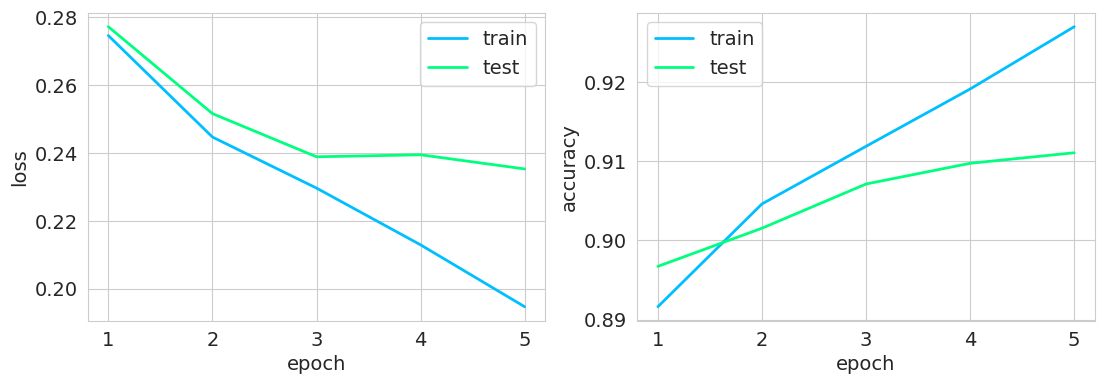

In [52]:
set_seed()
cnn = TextCNN(num_blocks=CLS_BLOCKS, num_channels=CLS_CHANNELS, num_classes=2).to(device)
cnn_optimizer = torch.optim.Adam(cnn.parameters(), lr=1e-3)
cnn_scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(cnn_optimizer, CLS_EPOCHS)

cnn_hist = train_classifier(cnn, cnn_optimizer, cnn_scheduler, nn.CrossEntropyLoss(), train_loader, test_loader, CLS_EPOCHS)
results['TextCNN (FastText emb.)'] = cnn_hist['valid_acc'][-1]

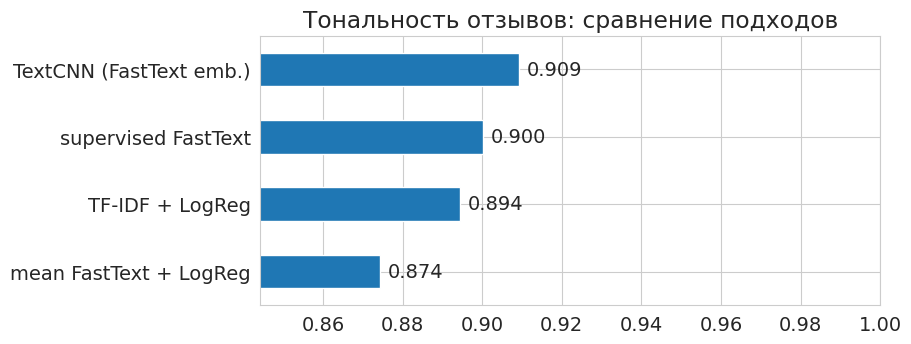

In [ ]:
res_df = pd.Series(results, name='test accuracy').sort_values().to_frame()
ax = res_df['test accuracy'].plot.barh(figsize=(8, 3.5), xlim=(res_df['test accuracy'].min() - 0.03, 1.0))
for i, v in enumerate(res_df['test accuracy']):
    ax.text(v + 0.002, i, f'{v:.3f}', va='center')
ax.set_title('Тональность отзывов: сравнение подходов')
plt.show()

> **Замечание про методологию.** Для простоты ту же тестовую выборку мы используем и как валидационную при обучении CNN (всего 5 эпох, без подбора гиперпараметров по ней). В реальной задаче нужен отдельный `val`, иначе оценка на тесте оптимистична.

### Задание 4
1. Поменяйте порог: считайте положительными только отзывы со `score == 5`. Как изменятся метрики? Что лучше смотреть вместо accuracy при дисбалансе классов?
2. Разморозьте эмбеддинги: сделайте их обучаемыми (`nn.Embedding.from_pretrained(..., freeze=False)`). Помогает ли это и что происходит с редкими словами?

# 5. Embedding drift

## Теория: что такое дрейф эмбеддингов

**Embedding drift** — изменение векторных представлений или их распределения во времени или между версиями модели. Под этим названием скрываются три разных явления, и важно их не смешивать:

| Тип | Что меняется | Пример | Как ловим |
|---|---|---|---|
| **1. Семантический (диахронический) дрейф** | *смысл слова* в языке | `broadcast`: «разбрасывать семена» → «вещать по радио/ТВ»; `awful`: «внушающий благоговение» → «ужасный» (Hamilton et al., 2016) | эмбеддинги, обученные на срезах разных лет → **выравнивание** → сравнение векторов слов |
| **2. Дрейф данных в продакшене** (data / covariate drift) | *распределение входных текстов* → распределение эмбеддингов | в отзывах появились новая функция, мемы, другой язык, спам-атака | статистические тесты между эталонной и текущей выборками эмбеддингов: сдвиг центроида, MMD, domain classifier |
| **3. Дрейф версии модели** (representation / model drift) | *сама модель-эмбеддер* (переобучение, обновление, смена провайдера) | вы дообучили эмбеддер или API-провайдер выкатил новую версию — векторы в индексе и свежие векторы **несовместимы** | сравнение векторов на одних и тех же «якорных» текстах, пересечение ближайших соседей |

### Почему пространства двух обученных моделей несравнимы

Косинусные близости (и значит, вся «семантика») не меняются при любом ортогональном преобразовании $Q$ ($Q^\top Q = I$):
$$(uQ)^\top (vQ) = u^\top Q Q^\top v = u^\top v$$
Значит, функция потерь одинакова для $E$ и $EQ$, и два запуска обучения с разными seed приходят к *«одному и тому же»* пространству, повёрнутому на неизвестный $Q$. Прямое сравнение координат (`cos(E₁[i], E₂[i])`) бессмысленно, а классификатор или индекс, обученный на $E_1$, на $E_2$ ломается.

### Orthogonal Procrustes: выравнивание пространств

Найти поворот, лучше всего совмещающий $X$ (старое пространство) с $Y$ (эталон) по набору «якорных» объектов:
$$R^{*}=\arg\min_{R^\top R=I}\|XR-Y\|_F^2\quad\Longrightarrow\quad R^{*}=UV^\top,\quad X^\top Y=U\Sigma V^\top\ (\text{SVD})$$
После выравнивания остаётся *реальный* дрейф: расстояние $1-\cos(x_iR^*, y_i)$ для каждого слова. Но у него есть **шумовой пол**: даже при одинаковых данных, но другом seed, выровненные векторы не совпадают идеально (особенно у редких слов). Поэтому реальный дрейф нужно сравнивать с базовой линией «тот же корпус, другой seed».

### Как детектировать дрейф распределения (тип 2)

Берём *эталонную* выборку эмбеддингов (например, обучающую) и *текущую* (окно продакшена) и сравниваем:
* **Сдвиг центроида**: $1-\cos(\bar x_{ref},\bar x_{cur})$ — быстро, ловит только сдвиг среднего.
* **MMD** (Maximum Mean Discrepancy, Gretton et al., 2012): расстояние между распределениями в пространстве признаков RBF-ядра, $\text{MMD}^2=\mathbb{E}\,k(x,x')+\mathbb{E}\,k(y,y')-2\,\mathbb{E}\,k(x,y)$. Ловит изменения формы распределения, не только среднего.
* **Domain classifier (C2ST)**: учим классификатор отличать «эталон» от «текущего»; ROC-AUC ≈ 0.5 — распределения неразличимы, → 1 — сильный дрейф. Плюс интерпретируем: можно посмотреть, какие тексты классификатор считает «новыми».

Пороги нужно калибровать по **шумовому полу** (сравнение двух выборок из одного и того же распределения).

## 5.1 Вращение пространства не меняет «смысл», но ломает координаты

Начнём с чистого численного эксперимента на уже обученных эмбеддингах Word2Vec: повернём их случайной ортогональной матрицей $Q$.

In [ ]:
from scipy.stats import ortho_group


def per_word_cos(X, Y):
    """Косинус между соответствующими строками двух матриц."""
    return (l2_normalize(X) * l2_normalize(Y)).sum(1)


def procrustes(src, tgt):
    """Ортогональная R, минимизирующая ||src @ R - tgt||_F."""
    U, _, Vt = np.linalg.svd(src.T @ tgt)
    return U @ Vt


def neighbor_overlap(X, Y, k=10, n_words=2000):
    """Средняя доля общих k ближайших соседей слова в пространствах X и Y. Не требует выравнивания (инвариантна к вращению)."""
    idx = np.arange(1, min(n_words, len(X) - 1) + 1)          # самые частые слова (индекс 0 — <unk>)

    def topk(E):
        En = l2_normalize(E)
        sims = En[idx] @ En.T
        sims[:, 0] = -np.inf
        sims[np.arange(len(idx)), idx] = -np.inf                # слово не сосед самому себе
        return np.argpartition(-sims, k, axis=1)[:, :k]

    a, b = topk(X), topk(Y)
    return float(np.mean([len(set(p) & set(q)) / k for p, q in zip(a, b)]))


Q = ortho_group.rvs(embed_matrix.shape[1], random_state=SEED)
rotated = embed_matrix @ Q

print(f'cos(слово в E, то же слово в E·Q):        {per_word_cos(embed_matrix, rotated)[1:].mean():+.3f}   <- координаты «разъехались»')
print(f'пересечение 10 ближайших соседей:          {neighbor_overlap(embed_matrix, rotated):.3f}   <- «смысл» не изменился')
R_hat = procrustes(l2_normalize(rotated), l2_normalize(embed_matrix))
print(f'cos после выравнивания Procrustes:         {per_word_cos(rotated @ R_hat, embed_matrix)[1:].mean():+.3f}   <- вращение восстановлено')
print('Классификатор поверх rotated, обученный на E, получил бы случайные признаки.')

cos(слово в E, то же слово в E·Q):        +0.009   <- координаты «разъехались»
пересечение 10 ближайших соседей:          1.000   <- «смысл» не изменился
cos после выравнивания Procrustes:         +1.000   <- вращение восстановлено
Классификатор поверх rotated, обученный на E, получил бы случайные признаки.


## 5.2 Семантический дрейф: эксперимент с контролируемым сдвигом смысла

В WikiText нет временных меток, поэтому смоделируем дрейф **синтетически и контролируемо**:

* **период 1** — исходный корпус;
* **период 2** — тот же корпус, где в 50 % случаев слово-донор (`river`) заменено на слово-цель (`film`). Для модели это выглядит так, будто `film` начал употребляться в новых контекстах — рядом с «водой», «мостами», «берегом».

Мы *знаем*, у какого слова сменился смысл, и можем проверить, находит ли его метод.

Обучаем **три** модели (по `DRIFT_EPOCHS` эпох — чтобы эксперимент поместился в семинар; на CPU уменьшите значение):

| модель | данные | seed | зачем |
|---|---|---|---|
| `E_A` | период 1 | 1 | эталон |
| `E_A2` | период 1 | 2 | **шумовой пол**: разница только в seed |
| `E_B` | период 2 | 3 | реальный дрейф + шум seed |

In [ ]:
DRIFT_EPOCHS = 5
DRIFT_TARGET, DRIFT_DONOR, DRIFT_P = 'film', 'river', 0.5

for w in (DRIFT_TARGET, DRIFT_DONOR):
    assert vocab[w] != 0, f'слова "{w}" нет в словаре — выберите другое слово-цель/донор'
    print(f'{w}: {vocab.counts[w]} вхождений в train')


def inject_drift(sentences, target, donor, p, seed=0):
    rng = random.Random(seed)
    return [[target if (t == donor and rng.random() < p) else t for t in sent] for sent in sentences]


train_data_period2 = inject_drift(train_data, DRIFT_TARGET, DRIFT_DONOR, DRIFT_P)
print('\nПример замены:')
src = next(s for s in train_data if DRIFT_DONOR in s)
print('  было :', ' '.join(src[:25]))
print('  стало:', ' '.join(inject_drift([src], DRIFT_TARGET, DRIFT_DONOR, 1.0)[0][:25]), '(при p=1)')

film: 1391 вхождений в train
river: 856 вхождений в train

Пример замены:
  было : most of the equipment , arms , and machinery at the little rock arsenal was removed to east of the mississippi river by order of
  стало: most of the equipment , arms , and machinery at the little rock arsenal was removed to east of the mississippi film by order of (при p=1)


In [ ]:
def train_w2v_embeddings(sentences, seed, epochs=DRIFT_EPOCHS):
    """Обучает Word2Vec с нуля на `sentences` (со словарём `vocab` из основного эксперимента) и возвращает матрицу эмбеддингов."""
    mdl, opt, sch, crit = build_w2v(seed=seed, num_epochs=epochs)
    loader = make_loader(sentences, shuffle=True)
    for epoch in range(epochs):
        w2v_training_epoch(mdl, opt, crit, loader, f'seed={seed}, epoch {epoch + 1}/{epochs}')
        sch.step()
    return mdl.embeds.weight.detach().cpu().numpy()


E_A = train_w2v_embeddings(train_data, seed=1)
E_A2 = train_w2v_embeddings(train_data, seed=2)
E_B = train_w2v_embeddings(train_data_period2, seed=3)
print('готово:', E_A.shape, E_A2.shape, E_B.shape)

/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:424: UserWarning: This DataLoader will create 4 worker processes in total. Our suggested max number of worker in current system is 2, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  self.check_worker_number_rationality()
/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:432: UserWarning: This DataLoader will create 4 worker processes in total. Our suggested max number of worker in current system is 2, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  self.check_worker_number_rationality()


seed=1, epoch 1/5:   0%|          | 0/1113 [00:00<?, ?it/s]

seed=1, epoch 2/5:   0%|          | 0/1113 [00:00<?, ?it/s]

seed=1, epoch 3/5:   0%|          | 0/1113 [00:00<?, ?it/s]

seed=1, epoch 4/5:   0%|          | 0/1113 [00:00<?, ?it/s]

seed=1, epoch 5/5:   0%|          | 0/1113 [00:00<?, ?it/s]

seed=2, epoch 1/5:   0%|          | 0/1113 [00:00<?, ?it/s]

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x79da10d64ea0>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1673, in _shutdown_workers
    w.join(timeout=_utils.MP_STATUS_CHECK_INTERVAL)
  File "/usr/lib/python3.13/multiprocessing/process.py", line 149, in join
    res = self._popen.wait(timeout)
  File "/usr/lib/python3.13/multiprocessing/popen_fork.py", line 41, in wait
    if not wait([self.sentinel], timeout):
  File "/usr/lib/python3.13/multiprocessing/connection.py", line 1174, in wait
    ready = selector.select(timeout)
  File "/usr/lib/python3.13/selectors.py", line 398, in select
    fd_event_list = self._selector.poll(timeout)
KeyboardInterrupt: 


KeyboardInterrupt: 

In [ ]:
# --- 1. Прямое сравнение без выравнивания (две модели на ОДНИХ данных, разные seed) ---
print(f'cos(E_A, E_A2) до выравнивания:    {per_word_cos(E_A, E_A2)[1:].mean():+.3f}')
print(f'пересечение соседей (top-10):       {neighbor_overlap(E_A, E_A2):.3f}   <- не зависит от вращения')

# --- 2. Выравнивание по «якорям» — всем словам, кроме слова-цели и донора ---
anchors = [i for i in range(1, VOCAB_SIZE) if i not in {vocab[DRIFT_TARGET], vocab[DRIFT_DONOR]}]
En_A, En_A2, En_B = l2_normalize(E_A), l2_normalize(E_A2), l2_normalize(E_B)

R_noise = procrustes(En_A2[anchors], En_A[anchors])
R_drift = procrustes(En_B[anchors], En_A[anchors])
A2_aligned, B_aligned = En_A2 @ R_noise, En_B @ R_drift

print(f'cos(E_A, E_A2) после выравнивания: {per_word_cos(A2_aligned, En_A)[1:].mean():+.3f}')
print(f'cos(E_A, E_B)  после выравнивания: {per_word_cos(B_aligned, En_A)[1:].mean():+.3f}   (ожидаем чуть ниже: помимо шума seed есть настоящий дрейф)')

cos(E_A, E_A2) до выравнивания:    -0.032
пересечение соседей (top-10):       0.735   <- не зависит от вращения
cos(E_A, E_A2) после выравнивания: +0.892
cos(E_A, E_B)  после выравнивания: +0.891   (ожидаем чуть ниже: помимо шума seed есть настоящий дрейф)


In [ ]:
# --- 3. Оценка дрейфа каждого слова и сравнение с шумовым полом ---
drift_df = pd.DataFrame({
    'word': vocab.itos,
    'freq': [vocab.counts[w] for w in vocab.itos],
    'noise': 1 - per_word_cos(A2_aligned, En_A),    # дрейф «из ничего»: только seed
    'drift': 1 - per_word_cos(B_aligned, En_A),     # seed + реальный сдвиг контекстов
}).iloc[1:]                                         # без <unk>
drift_df['excess'] = drift_df.drift - drift_df.noise
drift_df['rank'] = drift_df.excess.rank(ascending=False).astype(int)

print('Топ-10 слов по «избыточному» дрейфу (drift − noise):')
display(drift_df.sort_values('excess', ascending=False).head(10).round(3).reset_index(drop=True))
print('\nПозиции целевых слов:')
display(drift_df[drift_df.word.isin([DRIFT_TARGET, DRIFT_DONOR])].round(3))

Топ-10 слов по «избыточному» дрейфу (drift − noise):


,word,freq,noise,drift,excess,rank
0,film,1391,0.051,0.138,0.087,1
1,charitable,22,0.208,0.287,0.079,2
2,anselm,27,0.171,0.246,0.075,3
3,aires,27,0.267,0.338,0.070,4
4,bowlers,24,0.158,0.225,0.067,5
5,beeton,37,0.193,0.259,0.066,6
6,bonds,29,0.182,0.247,0.066,7
7,levine,21,0.164,0.228,0.064,8
8,puerto,32,0.180,0.242,0.062,9
9,domnall,27,0.157,0.218,0.061,10



Позиции целевых слов:


,word,freq,noise,drift,excess,rank
106,film,1391,0.051,0.138,0.087,1
185,river,856,0.015,0.018,0.002,3561


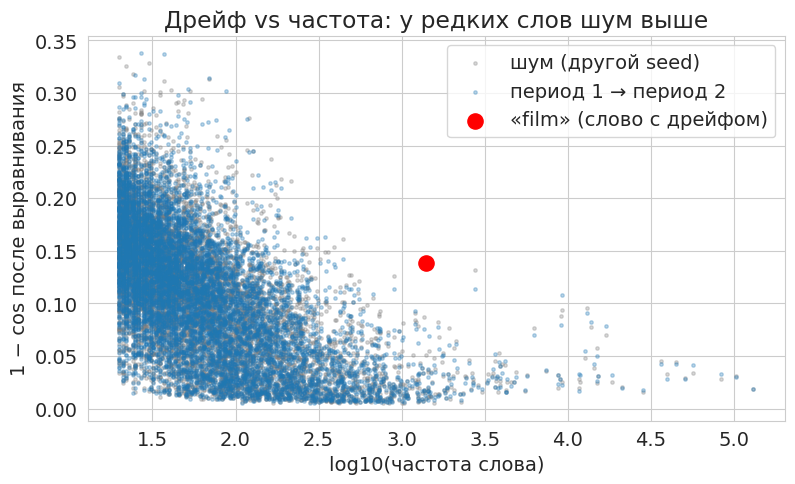

In [ ]:
fig, ax = plt.subplots(figsize=(9, 5))
ax.scatter(np.log10(drift_df.freq), drift_df.noise, s=6, alpha=0.3, color='gray', label='шум (другой seed)')
ax.scatter(np.log10(drift_df.freq), drift_df.drift, s=6, alpha=0.3, color='tab:blue', label='период 1 → период 2')
t = drift_df[drift_df.word == DRIFT_TARGET].iloc[0]
ax.scatter([np.log10(t.freq)], [t.drift], s=120, color='red', zorder=5, label=f'«{DRIFT_TARGET}» (слово с дрейфом)')
ax.set(xlabel='log10(частота слова)', ylabel='1 − cos после выравнивания',
       title='Дрейф vs частота: у редких слов шум выше')
ax.legend()
plt.show()

Два наблюдения, важных на практике:
1. **Шум зависит от частоты.** У редких слов эмбеддинги обычно нестабильны даже без дрейфа (проверьте на графике: серые точки должны подниматься к редким словам), поэтому наивное ранжирование по `1 − cos` засоряется редкими словами. Мы смотрим на `drift − noise` и сравниваем с базовой линией.
2. **Соседей можно сравнить без выравнивания.** Посмотрим на ближайших соседей слова-цели в двух пространствах:

In [ ]:
print('Период 1 (эталон):')
most_similar(DRIFT_TARGET, E_A, vocab, topn=10)
print('\nПериод 2 (после «дрейфа»):')
most_similar(DRIFT_TARGET, E_B, vocab, topn=10)
print('\nКонтроль — слово без дрейфа:')
most_similar('january', E_A, vocab, topn=6)
most_similar('january', E_B, vocab, topn=6);

Период 1 (эталон):
'film': video (0.87), album (0.86), soundtrack (0.84), award (0.84), novel (0.84), series (0.84), song (0.84), music (0.84), magazine (0.83), title (0.83)

Период 2 (после «дрейфа»):
'film': song (0.78), press (0.77), theatre (0.77), novel (0.77), program (0.77), festival (0.77), anime (0.77), newspaper (0.77), production (0.76), soundtrack (0.76)

Контроль — слово без дрейфа:
'january': november (1.00), april (0.99), june (0.99), october (0.99), december (0.99), february (0.99)
'january': april (1.00), november (0.99), february (0.99), december (0.99), october (0.99), june (0.99)


## 5.3 Дрейф версии модели: что ломается и как чинить

Типичная ситуация: у вас есть классификатор (или векторный индекс), построенный на эмбеддингах версии 1. Эмбеддер обновили — и новые вектора живут в другом (повёрнутом, слегка искажённом) пространстве. Смоделируем это на отзывах: «новая версия» эмбеддера = поворот $Q$ + небольшой шум.

> Версия 2 здесь **симулируется** (мы знаем, как она получена), реальная версия 2 — это другая модель. Но механика одна и та же: выравнивание по якорным текстам.

In [ ]:
rng = np.random.default_rng(SEED)
Q_ft = ortho_group.rvs(FT_DIM, random_state=SEED)
embeds_v2 = embeds_all @ Q_ft + rng.normal(scale=0.1 * embeds_all.std(), size=embeds_all.shape)   # «новая версия эмбеддера»

acc_v1 = lr_ft.score(test_embeds, y_test)
acc_v2_raw = lr_ft.score(embeds_v2[idx_test], y_test)

# Выравнивание по якорным текстам: достаточно пересчитать эмбеддинги ТОЛЬКО нескольких тысяч текстов в обеих версиях
anchor_idx = rng.choice(idx_train, size=3000, replace=False)
R_anchor = procrustes(embeds_v2[anchor_idx], embeds_all[anchor_idx])
acc_v2_aligned = lr_ft.score(embeds_v2[idx_test] @ R_anchor, y_test)

print(f'Классификатор на эмбеддингах v1:                    {acc_v1:.4f}')
print(f'Тот же классификатор на v2 БЕЗ выравнивания:         {acc_v2_raw:.4f}   <- «тихая» деградация, ошибок нет, метрики упали')
print(f'Тот же классификатор на v2 с выравниванием (3000 якорей): {acc_v2_aligned:.4f}')
print(f'\nМедиана cos(v1, v2) для одного и того же текста: до {np.median(per_word_cos(embeds_all[idx_test], embeds_v2[idx_test])):+.3f}, '
      f'после {np.median(per_word_cos(embeds_v2[idx_test] @ R_anchor, embeds_all[idx_test])):+.3f}')

Классификатор на эмбеддингах v1:                    0.8743
Тот же классификатор на v2 БЕЗ выравнивания:         0.4871   <- «тихая» деградация, ошибок нет, метрики упали
Тот же классификатор на v2 с выравниванием (3000 якорей): 0.8705

Медиана cos(v1, v2) для одного и того же текста: до +0.078, после +0.993


**Ключевой момент:** дрейф версии модели не вызывает исключений — пайплайн продолжает работать, но качество падает. Полезная практика — держать **«канареечный» набор текстов** (несколько сотен) с сохранёнными эмбеддингами и после каждого обновления эмбеддера сравнивать:
* `cos(старый вектор, новый вектор)` для каждого текста — резкое падение до ~0 = пространство повернулось, нужны выравнивание или переиндексация;
* пересечение ближайших соседей (`neighbor_overlap`) — показывает, изменилась ли именно *геометрия*, а не только система координат.

Если эмбеддер меняется кардинально (другая архитектура, другая размерность) — выравнивание не спасёт, придётся пересчитать эмбеддинги всей коллекции и переобучить модели поверх них.

## 5.4 Дрейф данных в продакшене: мониторинг распределения эмбеддингов

Теперь тип 2: модель не меняется, но меняются входные данные. Чтобы проверить, что метрики дрейфа вообще работают, снова сделаем **контролируемый эксперимент**:

* эталон — 1000 случайных отзывов из train;
* «продакшен-окно» — 1000 отзывов, в которых доля $\alpha$ заменена абзацами из Википедии (чужой домен, тексты обрезаны до 30 слов, чтобы различие не сводилось к длине).

При $\alpha=0$ окно взято из того же распределения — это **шумовой пол**; от него будем отсчитывать пороги. Все три метрики должны расти с $\alpha$.

In [ ]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import cross_val_score


def centroid_shift(ref, cur):
    a, b = ref.mean(0), cur.mean(0)
    return 1 - a @ b / (np.linalg.norm(a) * np.linalg.norm(b))


def mmd2_rbf(X, Y):
    """Несмещённая оценка MMD^2 с RBF-ядром; ширина ядра — медиана квадратов расстояний (median heuristic)."""
    Z = np.vstack([X, Y])
    sq = (Z ** 2).sum(1)
    d2 = np.clip(sq[:, None] + sq[None, :] - 2 * Z @ Z.T, 0, None)
    K = np.exp(-d2 / np.median(d2[np.triu_indices_from(d2, k=1)]))
    n = len(X)
    Kxx, Kyy, Kxy = K[:n, :n], K[n:, n:], K[:n, n:]
    m = len(Y)
    return (Kxx.sum() - np.trace(Kxx)) / (n * (n - 1)) + (Kyy.sum() - np.trace(Kyy)) / (m * (m - 1)) - 2 * Kxy.mean()


def domain_classifier_auc(X, Y, cv=5):
    """ROC-AUC классификатора «эталон vs текущее» (кросс-валидация). 0.5 — различить нельзя, 1.0 — дрейф очевиден."""
    Z = np.vstack([X, Y])
    labels = np.r_[np.zeros(len(X)), np.ones(len(Y))]
    clf = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000))
    return cross_val_score(clf, Z, labels, cv=cv, scoring='roc_auc').mean()


def drift_report(ref, cur):
    return {'centroid_shift': centroid_shift(ref, cur), 'mmd2': mmd2_rbf(ref, cur), 'domain_auc': domain_classifier_auc(ref, cur)}


# Эмбеддинги «чужого домена»: абзацы Википедии, 30 слов, без <unk>
wiki_sents = [[t for t in sent[:30] if t != '<unk>'] for sent in valid_data]
wiki_embeds = np.stack([get_sentence_embedding(s) for s in wiki_sents if s])
print('wiki:', wiki_embeds.shape)

wiki: (1898, 100)


In [ ]:
N_WINDOW, N_REPEATS = 1000, 3
rng = np.random.default_rng(SEED)
rows = []
for alpha in [0, 0.02, 0.05, 0.1, 0.2, 0.5]:
    n_wiki = int(alpha * N_WINDOW)
    for _ in range(N_REPEATS):
        ref = embeds_all[rng.choice(idx_train, N_WINDOW, replace=False)]
        cur = np.vstack([embeds_all[rng.choice(idx_test, N_WINDOW - n_wiki, replace=False)],
                         wiki_embeds[rng.choice(len(wiki_embeds), n_wiki, replace=False)]])
        rows.append({'alpha': alpha, **drift_report(ref, cur)})

drift_curve = pd.DataFrame(rows).groupby('alpha').mean()

fig, axs = plt.subplots(1, 3, figsize=(15, 4))
for ax, col in zip(axs, drift_curve.columns):
    ax.plot(drift_curve.index * 100, drift_curve[col], 'o-')
    ax.axhline(drift_curve[col].iloc[0], color='gray', linestyle='--', label='шумовой пол (α=0)')
    ax.set(xlabel='доля «чужих» текстов α, %', title=col)
    ax.legend()
plt.tight_layout()
plt.show()
drift_curve.round(4)

Метрики различаются по чувствительности: `centroid_shift` и `mmd2` измеряются в разных единицах и растут по-разному, а `domain_auc` удобен тем, что у него универсальная шкала 0.5 → 1. На практике смотрят на несколько метрик сразу и алертят по превышению порога, **откалиброванного по шумовому полу** (например, среднее + 3σ по значениям при α=0 на бутстрепе).

### Реальные данные: есть ли дрейф во времени?

В отзывах Bumble есть временная метка `at`. Разобьём отзывы по времени на 12 последовательных окон и сравним каждое окно с самым первым. Если настоящего дрейфа нет — кривые останутся на уровне шумового пола из эксперимента выше; если есть — поднимутся.

In [ ]:
if 'at' in data.columns:
    dates = pd.to_datetime(data['at'], errors='coerce')
    order = np.argsort(dates.values)[:dates.notna().sum()]            # NaT уходят в конец и отбрасываются
    chunks = np.array_split(order, 12)
    ref_idx = rng.choice(chunks[0], min(1500, len(chunks[0])), replace=False)

    rows = []
    for k, chunk in enumerate(chunks[1:], start=1):
        cur_idx = rng.choice(chunk, min(1500, len(chunk)), replace=False)
        rows.append({'window': k, 'date': dates.iloc[chunk].median(), **drift_report(embeds_all[ref_idx], embeds_all[cur_idx])})
    temporal = pd.DataFrame(rows).set_index('window')

    fig, axs = plt.subplots(1, 3, figsize=(15, 4))
    for ax, col in zip(axs, ['centroid_shift', 'mmd2', 'domain_auc']):
        ax.plot(temporal.index, temporal[col], 'o-', label='окна во времени')
        ax.axhline(drift_curve[col].iloc[0], color='gray', linestyle='--', label='шумовой пол')
        ax.set(xlabel='окно (по времени →)', title=col)
        ax.legend()
    plt.tight_layout()
    plt.show()
    display(temporal.round(4))
else:
    print('В датасете нет колонки "at" — пропускаем временной анализ; используйте синтетический эксперимент выше.')

## 5.5 Практический чек-лист: что делать с дрейфом

| Ситуация | Диагностика | Действие |
|---|---|---|
| Меняется входной поток (тип 2) | MMD / domain classifier на окнах эмбеддингов, мониторинг доли OOV и длины текстов | собрать свежие данные, дообучить модель, обновить эталон мониторинга |
| Обновилась модель-эмбеддер (тип 3) | канареечный набор: cos старый/новый вектор, пересечение соседей | выравнивание (Procrustes) по якорям — быстрый фикс; для необратимых изменений — переиндексация и переобучение |
| Меняется язык / значения слов (тип 1) | эмбеддинги по срезам времени + выравнивание, дрейф − шумовой пол | переобучать эмбеддинги периодически; для анализа — смотреть соседей слова в разные периоды |
| Всегда | версионировать эмбеддер вместе с индексом и моделью поверх, хранить версию рядом с каждым вектором | никогда не смешивать векторы разных версий в одном индексе |

**Типичные ошибки:**
* сравнивать координаты эмбеддингов разных запусков без выравнивания (вращение!);
* считать любое отличие дрейфом, не измерив **шумовой пол** (seed, размер выборки, частота слов);
* мониторить только качество модели: метки в проде появляются с задержкой, а дрейф эмбеддингов виден сразу и *без меток*.

# Итоги

* **Токенизация** определяет словарь, длину последовательностей и поведение на редких словах. Subword-методы убирают OOV почти полностью: **BPE** строит словарь слияниями, **Unigram LM** — удалением токенов из большого словаря по вероятностной модели и умеет давать *распределение* сегментаций (subword regularization).
* **Эмбеддинги** — обучаемая таблица `|V|×d`; **Word2Vec** учит её предсказанием контекста по дистрибутивной гипотезе. **FastText** добавляет символьные n-граммы и поэтому работает на опечатках и словах вне словаря.
* На задаче классификации тональности предобученные эмбеддинги не всегда бьют хороший TF-IDF; выигрыш даёт учёт порядка слов и/или адаптация эмбеддингов к домену.
* **Embedding drift** — это три разных явления (смысл слов, входные данные, версия модели). Эмбеддинги разных обучений **несовместимы** (вращение), их нужно выравнивать, а дрейф — сравнивать с **шумовым полом**.

## Что почитать

* Mikolov et al., *Efficient Estimation of Word Representations in Vector Space* (2013); *Distributed Representations of Words and Phrases and their Compositionality* (2013) — Word2Vec, negative sampling, subsampling.
* Bojanowski et al., *Enriching Word Vectors with Subword Information* (2017) — FastText.
* Sennrich et al., *Neural Machine Translation of Rare Words with Subword Units* (2016) — BPE для NLP.
* Kudo, *Subword Regularization: Improving Neural Network Translation Models with Multiple Subword Candidates* (2018) — Unigram LM; Kudo & Richardson, *SentencePiece* (2018).
* Levy & Goldberg, *Neural Word Embedding as Implicit Matrix Factorization* (2014).
* Hamilton, Leskovec, Jurafsky, *Diachronic Word Embeddings Reveal Statistical Laws of Semantic Change* (2016) — выравнивание Procrustes и измерение семантического дрейфа.
* Gretton et al., *A Kernel Two-Sample Test* (2012) — MMD; Rabanser et al., *Failing Loudly: An Empirical Study of Methods for Detecting Dataset Shift* (2019) — детекция дрейфа.
* Jurafsky & Martin, *Speech and Language Processing*, главы про токенизацию и векторную семантику.